# Step 4: Degree-preserving baselines (null models)

**Scope of this notebook.** Extended pilot, mixing diagnostics, the similarity benchmark, and generation and validation of the 600 production networks. It does not start Step 5, Step 6 or Step 7, and it performs no airport removals.

| Null model | Status | What is preserved |
|---|---|---|
| Directed degree-preserving | **Primary; the only null deciding H2** | Each airport's exact in-degree and out-degree |
| Reciprocal-pair | **Supplementary; no H2 verdict** | Each airport's exact in-degree and out-degree, and every route's reverse |

**Protocol clarifications recorded for implementation**

- **Removal count.** K = `(2 * N * p + 100) // 200`, where **p is in percentage points (5, 10, 15 or 20), not a decimal fraction**.
- **H2 classification.** *Supported*: at least two of the three strategies deviate systematically in the same direction. *Mixed*: systematic deviations occur in both directions, but neither direction has at least two strategies. *Not supported*: otherwise.

A failed validation or mixing condition stops this notebook. Invalid networks are never silently regenerated.

## Section 4.0: Setup and observed networks

In [1]:
import hashlib
import os
import platform
import time
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
import scipy.stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path

# Local execution is enabled only when this environment variable is set.
# It is not set on Colab, so Colab always uses the Google Drive path below.
LOCAL_PROJECT_ROOT = os.environ.get("NETWORK_ANALYSIS_LOCAL_ROOT")

if LOCAL_PROJECT_ROOT:
    BASE = Path(LOCAL_PROJECT_ROOT) / "Data"
else:
    from google.colab import drive
    drive.mount("/content/drive")

    # Notice the trailing space after 'Network Analysis '
    BASE = Path("/content/drive/MyDrive/Network Analysis /Data")

PROCESSED = BASE / "Processed"
NULLS = PROCESSED / "Nulls"
PROJECT_ROOT = BASE.parent
RESULTS = PROJECT_ROOT / "Results"
FIGURES = RESULTS / "Figures"
TABLES = RESULTS / "Tables"

NULLS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

AIRLINES = ["AA", "DL", "WN"]
MODELS = ["directed", "reciprocal"]
MODEL_LABELS = {"directed": "Primary directed null", "reciprocal": "Supplementary reciprocal-pair null"}

MASTER_SEED = 20250401
PILOT_CHAINS = 300
CHECKPOINT_MULTIPLIERS = [0.5, 1, 2, 5, 10, 20, 50, 100, 200]  # stability checkpoints; 200 x U is the reference
SUCCESS_ONLY_MULTIPLIERS = [250, 300, 350, 400]  # successful-swap counts only
MIN_SUCCESS_MULTIPLIER = 10
STABILITY_SD_FRACTION = 0.25
STABILITY_FLOOR = 0.001
N_NETWORKS = 100
RANDOM_TRIALS = 100
BOOTSTRAP_RESAMPLES = 1000
LOUVAIN_SEEDS = list(range(100))
LOUVAIN_RESOLUTION = 1.0
REMOVAL_PERCENTAGE_POINTS = [5, 10, 15, 20]
SIMILARITY_TOLERANCE = 0.01
BATCH_SIZE = 200_000

AIRLINE_INDEX = {a: i for i, a in enumerate(AIRLINES)}
MODEL_INDEX = {m: i for i, m in enumerate(MODELS)}
STAGE_INDEX = {"pilot": 1, "long_chain": 2, "nx_comparison": 3, "production": 4, "random_orders": 5, "bootstrap": 6}

runtime_log = {}
check_rows = []


class StopProtocolError(RuntimeError):
    """A protocol condition failed: stop and report; do not regenerate networks."""


def check(name, condition, detail=""):
    if not bool(condition):
        raise StopProtocolError(f"FAILED: {name}. {detail}")
    check_rows.append({"Check": name, "Result": "PASS", "Detail": str(detail)})


seed_registry_rows = []
software_record = {
    "Python": platform.python_version(), "NetworkX": nx.__version__, "NumPy": np.__version__,
    "pandas": pd.__version__, "SciPy": scipy.__version__, "Matplotlib": matplotlib.__version__,
    "Master seed": MASTER_SEED, "Pilot chains per airline and null model": PILOT_CHAINS,
    "Stability rule": "max(0.25 x SD(reference), 0.001); reference 200 x U",
    "Minimum successful swaps": "10 x U"
}


def save_records():
    pd.DataFrame(check_rows).to_csv(TABLES / "04_pilot_validation.csv", index=False)
    pd.DataFrame(seed_registry_rows).to_csv(TABLES / "04_pilot_seed_registry.csv", index=False)
    pd.DataFrame([{"Stage": key, "Seconds": value} for key, value in runtime_log.items()]).to_csv(
        TABLES / "04_pilot_runtime_log.csv", index=False
    )
    pd.DataFrame([software_record]).to_csv(TABLES / "04_pilot_run_metadata.csv", index=False)


def stop(message):
    save_records()
    raise StopProtocolError(message)


def paired_summary(earlier, reference_values):
    difference = earlier - reference_values
    n = len(difference)
    mean, sd = float(difference.mean()), float(difference.std(ddof=1))
    se = sd / np.sqrt(n)
    margin = float(scipy.stats.t.ppf(0.975, n - 1)) * se
    return {"Mean paired difference": mean, "SD paired differences": sd, "SE": se,
            "95% CI low": mean - margin, "95% CI high": mean + margin}


def child_seed(stage, airline, model, chain):
    """Reproducible child seed for one stochastic object, recorded in the seed registry."""
    key = (STAGE_INDEX[stage], AIRLINE_INDEX[airline], MODEL_INDEX.get(model, 9), int(chain))
    seed_registry_rows.append({
        "Stage": stage, "Airline": airline, "Model": model, "Chain or trial": int(chain),
        "Entropy": MASTER_SEED, "Spawn key": str(key)
    })
    return np.random.SeedSequence(entropy=MASTER_SEED, spawn_key=key)


def removal_count(n, p):
    """p is in percentage points (5, 10, 15 or 20); halves round up."""
    return (2 * n * p + 100) // 200


print("Processed directory exists:", PROCESSED.exists())
print("Master seed:", MASTER_SEED, "| pilot chains per airline and null model:", PILOT_CHAINS)

Processed directory exists: True
Master seed: 20250401 | pilot chains per airline and null model: 300


In [2]:
OBS = {}

for airline in AIRLINES:
    nodes = pd.read_csv(PROCESSED / f"{airline}_nodes.csv")
    edges = pd.read_csv(PROCESSED / f"{airline}_edges.csv")

    ids = np.sort(nodes["airport_id"].to_numpy(dtype=np.int64))
    n = len(ids)
    position = {int(v): i for i, v in enumerate(ids)}
    source = np.array([position[int(v)] for v in edges["source"]], dtype=np.int64)
    target = np.array([position[int(v)] for v in edges["target"]], dtype=np.int64)
    keys = np.sort(source * n + target)

    reverse_keys = target * n + source
    check(f"{airline}: observed network is fully reciprocal", np.isin(reverse_keys, keys).all())

    forward = source < target
    OBS[airline] = {
        "n": n, "m": len(source), "ids": ids, "codes": nodes.set_index("airport_id").loc[ids, "code"].to_numpy(),
        "source": source, "target": target, "keys": keys,
        "left": source[forward], "right": target[forward],
        "out": np.bincount(source, minlength=n), "in": np.bincount(target, minlength=n),
        "U": {"directed": len(source), "reciprocal": int(forward.sum())},
        "fingerprint": hashlib.sha256(np.sort(ids).tobytes() + keys.tobytes() + edges.sort_values(["source", "target"])["frequency"].to_numpy().tobytes()).hexdigest()
    }

expected_counts = {"AA": [12, 23, 35, 46], "DL": [11, 21, 32, 42], "WN": [5, 10, 16, 21]}

for airline, expected in expected_counts.items():
    assert [removal_count(OBS[airline]["n"], p) for p in REMOVAL_PERCENTAGE_POINTS] == expected

print(pd.DataFrame([
    {"Airline": a, "Airports N": OBS[a]["n"], "Directed routes m": OBS[a]["m"], "Reciprocal pairs": OBS[a]["U"]["reciprocal"]}
    for a in AIRLINES
]).to_string(index=False))

Airline  Airports N  Directed routes m  Reciprocal pairs
     AA         230               1808               904
     DL         212               1506               753
     WN         104               1792               896


## Section 4.1: Network generators and diagnostics

**Primary directed null.** One attempt draws two routes A→B and C→D uniformly and proposes A→D and C→B. It is rejected if A = C, B = D, a self-loop would arise, or a new route already exists. In- and out-degrees are unchanged by construction.

**Supplementary reciprocal-pair null.** Because every observed route has its reverse, the network is a set of reciprocal pairs. One attempt draws pairs {A,B} and {C,D} and one of the two possible reconnections with probability 1/2. It is rejected if the four airports are not distinct or a new pair already exists. A successful swap replaces four directed routes at once, so every route keeps its reverse.

**Why attempts, not successes, define chain length.** A rejected attempt leaves the network unchanged but still counts as a step. Stopping after a fixed number of *successful* swaps would bias sampling toward networks with more valid swaps.

In [3]:
def run_directed_chain(source, target, n, attempts, seed_sequence, checkpoints=()):
    rng = np.random.default_rng(seed_sequence)
    src, dst = source.tolist(), target.tolist()
    m = len(src)
    present = {s * n + t for s, t in zip(src, dst)}
    successes, done, snapshots = 0, 0, []

    for mark in sorted(set(checkpoints) | {attempts}):
        while done < mark:
            size = min(BATCH_SIZE, mark - done)
            first = rng.integers(0, m, size).tolist()
            second = rng.integers(0, m, size).tolist()

            for i, j in zip(first, second):
                a, b, c, d = src[i], dst[i], src[j], dst[j]
                if a == c or b == d or a == d or c == b:
                    continue
                new_one, new_two = a * n + d, c * n + b
                if new_one in present or new_two in present:
                    continue
                present.remove(a * n + b)
                present.remove(c * n + d)
                present.add(new_one)
                present.add(new_two)
                dst[i], dst[j] = d, b
                successes += 1

            done += size
        snapshots.append({"attempts": mark, "successes": successes,
                          "source": np.array(src, dtype=np.int64), "target": np.array(dst, dtype=np.int64)})

    return snapshots


def run_reciprocal_chain(left, right, n, attempts, seed_sequence, checkpoints=()):
    rng = np.random.default_rng(seed_sequence)
    first_end, second_end = left.tolist(), right.tolist()
    pairs = len(first_end)
    present = {min(a, b) * n + max(a, b) for a, b in zip(first_end, second_end)}
    successes, done, snapshots = 0, 0, []

    for mark in sorted(set(checkpoints) | {attempts}):
        while done < mark:
            size = min(BATCH_SIZE, mark - done)
            first = rng.integers(0, pairs, size).tolist()
            second = rng.integers(0, pairs, size).tolist()
            flips = rng.integers(0, 2, size).tolist()

            for i, j, flip in zip(first, second, flips):
                a, b, c, d = first_end[i], second_end[i], first_end[j], second_end[j]
                if a == c or a == d or b == c or b == d:
                    continue
                if flip:
                    p, q, r, s = a, d, c, b
                else:
                    p, q, r, s = a, c, b, d
                new_one, new_two = min(p, q) * n + max(p, q), min(r, s) * n + max(r, s)
                if new_one in present or new_two in present:
                    continue
                present.remove(min(a, b) * n + max(a, b))
                present.remove(min(c, d) * n + max(c, d))
                present.add(new_one)
                present.add(new_two)
                first_end[i], second_end[i], first_end[j], second_end[j] = p, q, r, s
                successes += 1

            done += size

        ends_one, ends_two = np.array(first_end, dtype=np.int64), np.array(second_end, dtype=np.int64)
        snapshots.append({"attempts": mark, "successes": successes,
                          "source": np.concatenate([ends_one, ends_two]),
                          "target": np.concatenate([ends_two, ends_one])})

    return snapshots


def run_chain(airline, model, attempts, seed_sequence, checkpoints=()):
    obs = OBS[airline]
    if model == "directed":
        return run_directed_chain(obs["source"], obs["target"], obs["n"], attempts, seed_sequence, checkpoints)
    return run_reciprocal_chain(obs["left"], obs["right"], obs["n"], attempts, seed_sequence, checkpoints)


def directed_matrix(source, target, n):
    return csr_matrix((np.ones(len(source), dtype=float), (source, target)), shape=(n, n))


def undirected_matrix(A):
    B = (A + A.T).tocsr()
    B.data[:] = 1.0
    return B


def evaluate_connectivity(A, universe_n):
    """Efficiency, reachability and largest SCC using the original airport count as universe."""
    d = shortest_path(A, method="D", unweighted=True, directed=True)
    reachable = np.isfinite(d) & (d > 0)
    denominator = universe_n * (universe_n - 1)
    labels = connected_components(A, directed=True, connection="strong")[1]
    return {
        "Efficiency": float((1.0 / d[reachable]).sum() / denominator),
        "Reachability": float(reachable.sum() / denominator),
        "Largest SCC": float(np.bincount(labels).max() / universe_n),
        "Number of SCCs": int(labels.max() + 1),
        "Mean reachable path length": float(d[reachable].mean())
    }


def reciprocity_of(A):
    return float(A.multiply(A.T).sum() / A.sum())


def closure_measures(B):
    k = np.asarray(B.sum(axis=1)).ravel()
    closed = (B @ B @ B).diagonal()
    usable = k >= 2
    local = np.zeros(B.shape[0])
    local[usable] = closed[usable] / (k[usable] * (k[usable] - 1))
    return float(closed.sum() / (k * (k - 1)).sum()), float(local.mean())


def degree_correlation(values_a, values_b):
    return float(np.corrcoef(values_a, values_b)[0, 1])


DIAGNOSTICS = ["Edge overlap", "Reciprocity", "Out-in assortativity", "Transitivity",
               "Intact efficiency", "Intact reachability", "Intact largest SCC"]
MODEL_DIAGNOSTICS = {"directed": DIAGNOSTICS, "reciprocal": [d for d in DIAGNOSTICS if d != "Reciprocity"]}


def mixing_diagnostics(airline, source, target):
    obs = OBS[airline]
    A = directed_matrix(source, target, obs["n"])
    connectivity = evaluate_connectivity(A, obs["n"])
    return {
        "Edge overlap": float(np.isin(obs["keys"], source * obs["n"] + target).mean()),
        "Reciprocity": reciprocity_of(A),
        "Out-in assortativity": degree_correlation(obs["out"][source], obs["in"][target]),
        "Transitivity": closure_measures(undirected_matrix(A))[0],
        "Intact efficiency": connectivity["Efficiency"],
        "Intact reachability": connectivity["Reachability"],
        "Intact largest SCC": connectivity["Largest SCC"]
    }


def stability_tolerance(reference_sd):
    return max(STABILITY_SD_FRACTION * reference_sd, STABILITY_FLOOR)


print("Generators and diagnostics defined.")

Generators and diagnostics defined.


## Section 4.2: Pilot chains and swap counts

Three hundred independent chains per airline and model are measured at 0.5 to 200 × U attempts, where U is the number of directed routes (primary) or reciprocal pairs (supplementary). Chains continue to 400 × U, and successful swaps are also counted at 250, 300, 350 and 400 × U. Those extra counts are used only for the 10 × U requirement.

**Stability rule.** For each diagnostic, airline and model, D̄ and SD are the mean and sample SD (ddof = 1) across the 300 chains at a checkpoint. Checkpoint c passes when |D̄(c) − D̄(200U)| ≤ max(0.25 × SD(200U), 0.001). The SD is taken at the reference checkpoint because the chains share one starting network, so early SDs are artificially small.

**Setting the chain length.** B is the earliest checkpoint from which all diagnostics pass through the last checkpoint. A10 is the first checkpoint where every chain has at least 10 × U successful swaps. T = max(2B, A10) attempts.

In [4]:
started = time.perf_counter()
pilot_rows = []

for airline in AIRLINES:
    for model in MODELS:
        U = OBS[airline]["U"][model]
        all_multipliers = CHECKPOINT_MULTIPLIERS + SUCCESS_ONLY_MULTIPLIERS
        marks = [int(np.ceil(multiplier * U)) for multiplier in all_multipliers]

        for chain in range(PILOT_CHAINS):
            snapshots = run_chain(airline, model, marks[-1], child_seed("pilot", airline, model, chain), marks)

            for multiplier, snapshot in zip(all_multipliers, snapshots):
                diagnostics = (mixing_diagnostics(airline, snapshot["source"], snapshot["target"])
                               if multiplier in CHECKPOINT_MULTIPLIERS else {})
                pilot_rows.append({
                    "Airline": airline, "Model": model, "Chain": chain, "Multiplier of U": multiplier,
                    "Attempts": snapshot["attempts"], "Successful swaps": snapshot["successes"], **diagnostics
                })

pilot_df = pd.DataFrame(pilot_rows)
pilot_df.to_csv(TABLES / "04_pilot_chain_diagnostics.csv", index=False)
runtime_log["Pilot chains"] = time.perf_counter() - started
save_records()
print(f"Pilot rows: {len(pilot_df):,}")

Pilot rows: 23,400


In [5]:
stability_rows, settings_rows, pilot_failures = [], [], []
SWAP_SETTINGS = {}

for airline in AIRLINES:
    for model in MODELS:
        U = OBS[airline]["U"][model]
        subset = pilot_df[(pilot_df["Airline"] == airline) & (pilot_df["Model"] == model)]
        by_mark = subset.groupby("Multiplier of U")
        reference = by_mark.get_group(CHECKPOINT_MULTIPLIERS[-1])
        passes_at = {multiplier: True for multiplier in CHECKPOINT_MULTIPLIERS}

        for diagnostic in MODEL_DIAGNOSTICS[model]:
            reference_mean = reference[diagnostic].mean()
            reference_sd = reference[diagnostic].std(ddof=1)
            tolerance = stability_tolerance(reference_sd)

            for multiplier in CHECKPOINT_MULTIPLIERS:
                values = by_mark.get_group(multiplier)[diagnostic]
                difference = abs(values.mean() - reference_mean)
                passed = difference <= tolerance
                passes_at[multiplier] = passes_at[multiplier] and passed
                stability_rows.append({
                    "Airline": airline, "Model": model, "Diagnostic": diagnostic,
                    "Multiplier of U": multiplier, "Mean": values.mean(), "SD across chains": values.std(ddof=1),
                    "Reference mean": reference_mean, "Reference SD": reference_sd,
                    "Absolute difference": difference, "Tolerance": tolerance, "Pass": passed
                })

        burn_in_multiplier = None
        for index, multiplier in enumerate(CHECKPOINT_MULTIPLIERS):
            if all(passes_at[later] for later in CHECKPOINT_MULTIPLIERS[index:]):
                burn_in_multiplier = multiplier
                break

        if burn_in_multiplier is None or burn_in_multiplier == CHECKPOINT_MULTIPLIERS[-1]:
            pilot_failures.append(f"{airline} {model}: no checkpoint stabilized before the 200 x U reference")
            continue

        floor = MIN_SUCCESS_MULTIPLIER * U
        minimum_success = by_mark["Successful swaps"].min()
        qualifying = minimum_success[minimum_success >= floor]
        if qualifying.empty:
            pilot_failures.append(f"{airline} {model}: not all chains reached {floor} successful swaps by 400 x U")
            continue

        a10 = int(np.ceil(qualifying.index.min() * U))
        b_attempts = int(np.ceil(burn_in_multiplier * U))
        T = max(2 * b_attempts, a10)
        SWAP_SETTINGS[(airline, model)] = {"T": T, "floor": floor, "U": U}

        settings_rows.append({
            "Airline": airline, "Model": model, "Unit U": U,
            "B multiplier": burn_in_multiplier, "B attempts": b_attempts,
            "A10 attempts": a10, "Pilot T attempts": T, "T / U": T / U,
            "Minimum successful swaps required (10 x U)": floor,
            "Pilot acceptance rate at 200 x U": float(
                (reference["Successful swaps"] / reference["Attempts"]).mean()
            )
        })

pilot_stability_df = pd.DataFrame(stability_rows)
pilot_settings_df = pd.DataFrame(settings_rows)
pilot_stability_df.to_csv(TABLES / "04_pilot_stability.csv", index=False)
pilot_settings_df.to_csv(TABLES / "04_pilot_swap_settings.csv", index=False)

display(pilot_settings_df.round(3))
display(pilot_stability_df.pivot_table(index=["Airline", "Model"], columns="Multiplier of U", values="Pass", aggfunc="sum").astype(int))

if pilot_failures:
    stop("; ".join(pilot_failures))

for airline, model in SWAP_SETTINGS:
    check(f"{airline} {model}: stability and successful-swap requirements met in pilot", True)

,Airline,Model,Unit U,B multiplier,B attempts,A10 attempts,Pilot T attempts,T / U,Minimum successful swaps required (10 x U),Pilot acceptance rate at 200 x U
0,AA,directed,1808,50,90400,452000,452000,250.0,18080,0.044
1,AA,reciprocal,904,50,45200,226000,226000,250.0,9040,0.044
2,DL,directed,1506,50,75300,301200,301200,200.0,15060,0.058
3,DL,reciprocal,753,20,15060,150600,150600,200.0,7530,0.058
4,WN,directed,1792,20,35840,358400,358400,200.0,17920,0.099
5,WN,reciprocal,896,20,17920,179200,179200,200.0,8960,0.099


Multiplier of U     0.5    1.0    2.0    5.0    10.0   20.0   50.0   100.0  \
Airline Model                                                                
AA      directed        5      5      5      4      5      6      7      7   
        reciprocal      5      5      5      5      5      5      6      6   
DL      directed        4      5      4      4      6      6      7      7   
        reciprocal      4      5      5      5      5      6      6      6   
WN      directed        2      2      3      5      6      7      7      7   
        reciprocal      2      2      3      5      5      6      6      6   

Multiplier of U     200.0  
Airline Model              
AA      directed        7  
        reciprocal      6  
DL      directed        7  
        reciprocal      6  
WN      directed        7  
        reciprocal      6

## Section 4.3: Long-chain and swap-method checks

**Long-chain test.** Three hundred new chains run to 4T, and each chain is measured at both T and 4T. Each diagnostic must satisfy |D̄(T) − D̄(4T)| ≤ max(0.25 × SD(4T), 0.001), with SD across the 300 chains at 4T. If it fails, T is doubled and retested once. A second failure stops the notebook.

In [6]:
started = time.perf_counter()
long_rows, long_chain_rows, long_final, long_at_T = [], [], {}, {}

for airline in AIRLINES:
    for model in MODELS:
        settings = SWAP_SETTINGS[(airline, model)]
        current_T = settings["T"]

        for attempt_round in range(2):
            at_T, at_4T, finals = [], [], []

            for chain in range(PILOT_CHAINS):
                seed = child_seed("long_chain", airline, model, 1000 * attempt_round + chain)
                snapshots = run_chain(airline, model, 4 * current_T, seed, [current_T, 4 * current_T])
                first, last = snapshots[0], snapshots[-1]
                at_T.append({"Successful swaps": first["successes"], "source": first["source"], "target": first["target"],
                             **mixing_diagnostics(airline, first["source"], first["target"])})
                at_4T.append({"Successful swaps": last["successes"], "source": last["source"], "target": last["target"],
                              **mixing_diagnostics(airline, last["source"], last["target"])})
                for checkpoint, row in [("T", at_T[-1]), ("4T", at_4T[-1])]:
                    long_chain_rows.append({
                        "Airline": airline, "Model": model, "Test round": attempt_round + 1, "Chain": chain,
                        "Checkpoint": checkpoint, "T attempts": current_T, "Successful swaps": row["Successful swaps"],
                        **{d: row[d] for d in MODEL_DIAGNOSTICS[model]}
                    })

            all_pass = True

            for diagnostic in MODEL_DIAGNOSTICS[model]:
                values_T = np.array([row[diagnostic] for row in at_T])
                values_4T = np.array([row[diagnostic] for row in at_4T])
                reference_sd = values_4T.std(ddof=1)
                tolerance = stability_tolerance(reference_sd)
                difference = abs(values_T.mean() - values_4T.mean())
                passed = difference <= tolerance
                all_pass = all_pass and passed
                long_rows.append({
                    "Airline": airline, "Model": model, "Test round": attempt_round + 1, "T attempts": current_T,
                    "Diagnostic": diagnostic, "Mean at T": values_T.mean(), "Mean at 4T": values_4T.mean(),
                    "SD at 4T": reference_sd, "Absolute difference": difference, "Tolerance": tolerance, "Pass": passed,
                    **paired_summary(values_T, values_4T)
                })

            if all_pass:
                break
            if attempt_round == 1:
                pd.DataFrame(long_rows).to_csv(TABLES / "04_long_chain_test.csv", index=False)
                pd.DataFrame(long_chain_rows).to_csv(TABLES / "04_long_chain_by_chain.csv", index=False)
                stop(f"{airline} {model}: long-chain test failed twice.")
            current_T *= 2

        settings["T"] = current_T
        settings["long_chain_rounds"] = attempt_round + 1
        long_at_T[(airline, model)] = at_T
        long_final[(airline, model)] = at_4T

long_chain_df = pd.DataFrame(long_rows)
long_chain_df.to_csv(TABLES / "04_long_chain_test.csv", index=False)
pd.DataFrame(long_chain_rows).to_csv(TABLES / "04_long_chain_by_chain.csv", index=False)
runtime_log["Long-chain test"] = time.perf_counter() - started
save_records()

for (airline, model), settings in SWAP_SETTINGS.items():
    check(f"{airline} {model}: long-chain test passed", True, f"T = {settings['T']}, rounds = {settings['long_chain_rounds']}")

display(long_chain_df.groupby(["Airline", "Model", "Test round", "T attempts"])["Pass"].agg(["sum", "count"]))

sum  count
Airline Model      Test round T attempts            
AA      directed   1          452000        7      7
        reciprocal 1          226000        6      6
DL      directed   1          301200        7      7
        reciprocal 1          150600        6      6
WN      directed   1          358400        7      7
        reciprocal 1          179200        6      6

## Pilot report

The paired tables report each diagnostic's within-chain difference from its reference checkpoint. The approved pass/fail rule remains the difference in means against max(0.25 × SD(reference), 0.001). The dependence table shows how diagnostics move together across the same chains. The earlier 93% all-gates figure was an approximate planning estimate, not a guaranteed probability.

In [7]:
paired_rows, dependence_rows = [], []

for airline in AIRLINES:
    for model in MODELS:
        subset = pilot_df[(pilot_df["Airline"] == airline) & (pilot_df["Model"] == model)]
        reference = subset[subset["Multiplier of U"] == 200].sort_values("Chain")

        for diagnostic in MODEL_DIAGNOSTICS[model]:
            reference_values = reference[diagnostic].to_numpy(float)
            tolerance = stability_tolerance(reference_values.std(ddof=1))

            for multiplier in CHECKPOINT_MULTIPLIERS[:-1]:
                earlier = subset[subset["Multiplier of U"] == multiplier].sort_values("Chain")[diagnostic].to_numpy(float)
                summary = paired_summary(earlier, reference_values)
                paired_rows.append({
                    "Airline": airline, "Model": model, "Diagnostic": diagnostic, "Multiplier of U": multiplier,
                    **summary, "Tolerance": tolerance,
                    "Reference SD": float(reference_values.std(ddof=1)),
                    "Correlation with reference": float(np.corrcoef(earlier, reference_values)[0, 1]) if earlier.std() > 0 and reference_values.std() > 0 else np.nan,
                    "Pass approved rule": abs(summary["Mean paired difference"]) <= tolerance
                })

        at_100 = subset[subset["Multiplier of U"] == 100].sort_values("Chain")
        sets = {
            "Values at 200 x U": reference[MODEL_DIAGNOSTICS[model]].astype(float).reset_index(drop=True),
            "Paired differences 100 x U minus 200 x U": (
                at_100[MODEL_DIAGNOSTICS[model]].astype(float).reset_index(drop=True)
                - reference[MODEL_DIAGNOSTICS[model]].astype(float).reset_index(drop=True)
            )
        }

        for label, frame in sets.items():
            usable = frame.loc[:, frame.std(ddof=1) > 0]
            correlation = usable.corr()
            for first, second in combinations(correlation.columns, 2):
                dependence_rows.append({
                    "Airline": airline, "Model": model, "Set": label,
                    "Diagnostic A": first, "Diagnostic B": second, "Pearson correlation": float(correlation.loc[first, second])
                })

paired_df = pd.DataFrame(paired_rows)
dependence_df = pd.DataFrame(dependence_rows)
paired_df.to_csv(TABLES / "04_pilot_paired_differences.csv", index=False)
dependence_df.to_csv(TABLES / "04_pilot_diagnostic_dependence.csv", index=False)

display(paired_df[paired_df["Multiplier of U"] == 100].round(5))
display(dependence_df.pivot_table(index=["Set", "Diagnostic A", "Diagnostic B"], columns=["Airline", "Model"], values="Pearson correlation").round(2))

,Airline,Model,Diagnostic,Multiplier of U,Mean paired difference,SD paired differences,SE,95% CI low,95% CI high,Tolerance,Reference SD,Correlation with reference,Pass approved rule
7,AA,directed,Edge overlap,100.0,0.00071,0.00826,0.00048,-0.00023,0.00165,0.00154,0.00615,0.10036,True
15,AA,directed,Reciprocity,100.0,0.00077,0.01226,0.00071,-0.00062,0.00217,0.00214,0.00855,-0.08357,True
23,AA,directed,Out-in assortativity,100.0,0.00003,0.00037,0.00002,-0.00002,0.00007,0.00100,0.00026,-0.03109,True
31,AA,directed,Transitivity,100.0,-0.00032,0.00177,0.00010,-0.00052,-0.00011,0.00100,0.00124,-0.00739,True
39,AA,directed,Intact efficiency,100.0,0.00000,0.00090,0.00005,-0.00010,0.00010,0.00100,0.00066,0.06518,True
47,AA,directed,Intact reachability,100.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00100,0.00000,NaN,True
55,AA,directed,Intact largest SCC,100.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00100,0.00000,NaN,True
63,AA,reciprocal,Edge overlap,100.0,-0.00004,0.01169,0.00067,-0.00137,0.00129,0.00210,0.00840,-0.01370,True
71,AA,reciprocal,Out-in assortativity,100.0,0.00003,0.00050,0.00003,-0.00003,0.00008,0.00100,0.00033,-0.04365,True
79,AA,reciprocal,Transitivity,100.0,-0.00003,0.00039,0.00002,-0.00007,0.00002,0.00100,0.00024,-0.01393,True


Airline                                                                                  AA  \
Model                                                                              directed   
Set                                      Diagnostic A         Diagnostic B                    
Paired differences 100 x U minus 200 x U Edge overlap         Intact efficiency       -0.12   
                                                              Out-in assortativity     0.11   
                                                              Reciprocity              0.00   
                                                              Transitivity            -0.05   
                                         Out-in assortativity Intact efficiency       -0.61   
                                                              Transitivity            -0.11   
                                         Reciprocity          Intact efficiency       -0.03   
                                                              Out-in assortativity    -0.00   
                                                              Transitivity             0.06   
                                         Transitivity         Intact efficiency       -0.01   
Values at 200 x U                        Edge overlap         Intact efficiency       -0.12   
                                                              Out-in assortativity     0.14   
                                                              Reciprocity             -0.00   
                                                              Transitivity            -0.02   
                                         Out-in assortativity Intact efficiency       -0.59   
                                                              Transitivity            -0.12   
                                         Reciprocity          Intact efficiency       -0.03   
                                                              Out-in assortativity     0.03   
                                                              Transitivity             0.02   
                                         Transitivity         Intact efficiency       -0.04   

Airline                                                                                        \
Model                                                                              reciprocal   
Set                                      Diagnostic A         Diagnostic B                      
Paired differences 100 x U minus 200 x U Edge overlap         Intact efficiency         -0.08   
                                                              Out-in assortativity       0.08   
                                                              Reciprocity                 NaN   
                                                              Transitivity               0.14   
                                         Out-in assortativity Intact efficiency         -0.62   
                                                              Transitivity               0.43   
                                         Reciprocity          Intact efficiency           NaN   
                                                              Out-in assortativity        NaN   
                                                              Transitivity                NaN   
                                         Transitivity         Intact efficiency         -0.05   
Values at 200 x U                        Edge overlap         Intact efficiency         -0.01   
                                                              Out-in assortativity       0.06   
                                                              Reciprocity                 NaN   
                                                              Transitivity               0.16   
                                         Out-in assortativity Intact efficiency         -0.63   
                                                              Transi

,Airline,Model,Unit U,B multiplier,A10 attempts,Proposed attempted swaps T,T / U,Minimum successful swaps required,"Successes at T, minimum across long-chain chains","Successes at T, median across long-chain chains",Long-chain test rounds
0,AA,directed,1808,50,452000,452000,250.0,18080,19671,19980.0,1
1,AA,reciprocal,904,50,226000,226000,250.0,9040,9705,9998.5,1
2,DL,directed,1506,50,301200,301200,200.0,15060,16885,17311.0,1
3,DL,reciprocal,753,20,150600,150600,200.0,7530,8359,8658.0,1
4,WN,directed,1792,20,358400,358400,200.0,17920,34983,35428.5,1
5,WN,reciprocal,896,20,179200,179200,200.0,8960,17396,17726.0,1


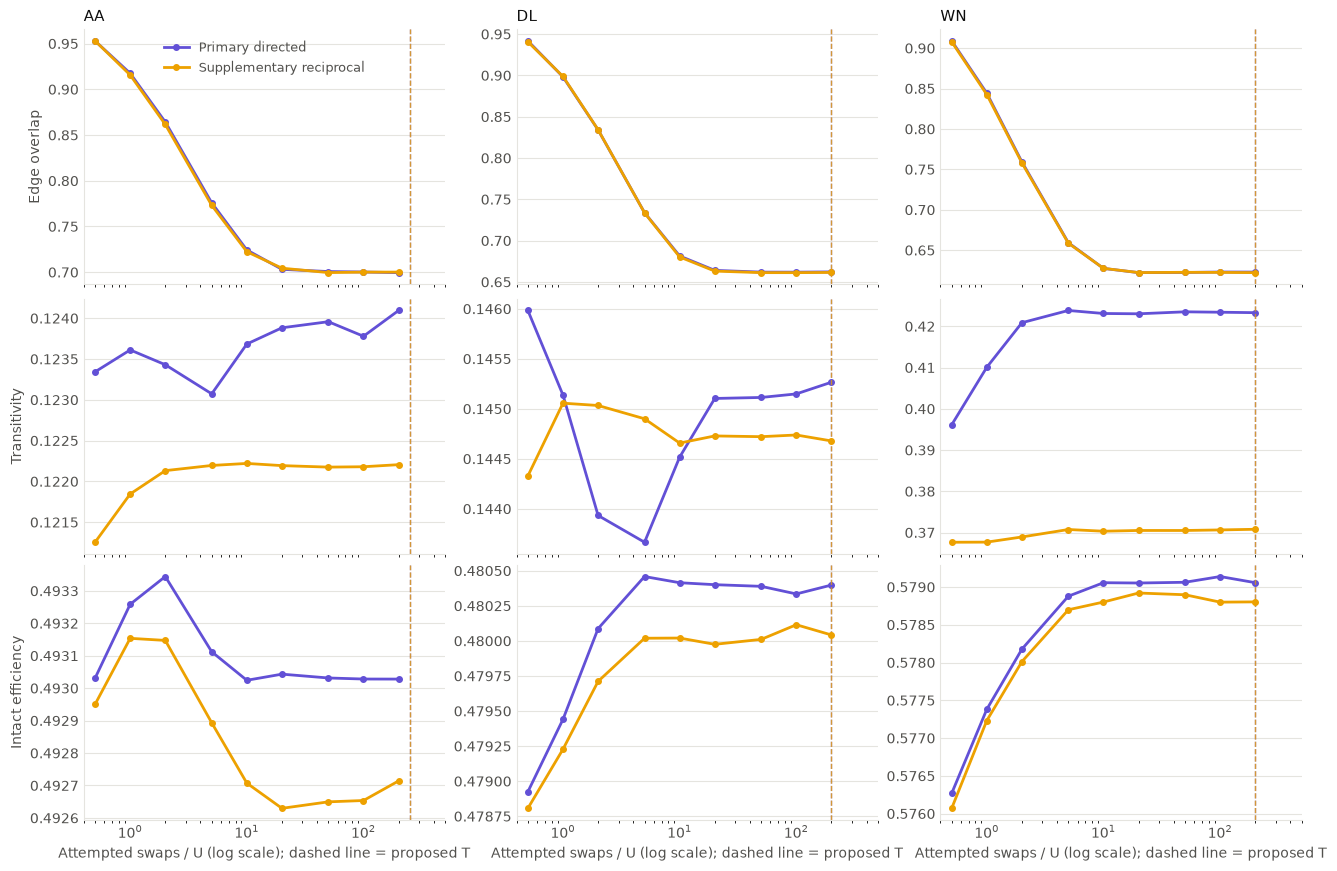

21 checks recorded so far.


In [8]:
proposal_rows = []

for (airline, model), settings in SWAP_SETTINGS.items():
    at_T = long_at_T[(airline, model)]
    successes = np.array([row["Successful swaps"] for row in at_T])
    row = pilot_settings_df[(pilot_settings_df["Airline"] == airline) & (pilot_settings_df["Model"] == model)].iloc[0]
    proposal_rows.append({
        "Airline": airline, "Model": model, "Unit U": settings["U"],
        "B multiplier": row["B multiplier"], "A10 attempts": row["A10 attempts"],
        "Proposed attempted swaps T": settings["T"], "T / U": settings["T"] / settings["U"],
        "Minimum successful swaps required": settings["floor"],
        "Successes at T, minimum across long-chain chains": int(successes.min()),
        "Successes at T, median across long-chain chains": float(np.median(successes)),
        "Long-chain test rounds": settings["long_chain_rounds"]
    })

proposal_df = pd.DataFrame(proposal_rows)
proposal_df.to_csv(TABLES / "04_proposed_production_swap_counts.csv", index=False)
display(proposal_df.round(2))

for row in proposal_df.itertuples(index=False):
    check(f"{row.Airline} {row.Model}: every long-chain chain met the successful-swap minimum at T",
          row[8] >= row[7], f"minimum {row[8]}, required {row[7]}")

INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e5e4df"
MODEL_COLORS = {"directed": "#6250d6", "reciprocal": "#eda100"}
MODEL_SHORT = {"directed": "Primary directed", "reciprocal": "Supplementary reciprocal"}


def style_axis(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(3, 3, figsize=(13, 8.6), constrained_layout=True, sharex=True)
diagnostic_data = pilot_df[pilot_df["Multiplier of U"].isin(CHECKPOINT_MULTIPLIERS)]

for column, airline in enumerate(AIRLINES):
    for row, diagnostic in enumerate(["Edge overlap", "Transitivity", "Intact efficiency"]):
        ax = axes[row, column]

        for model in MODELS:
            data = diagnostic_data[(diagnostic_data["Airline"] == airline) & (diagnostic_data["Model"] == model)]
            mean = data.groupby("Multiplier of U")[diagnostic].mean()
            ax.plot(mean.index, mean.values, marker="o", markersize=4, linewidth=2,
                    color=MODEL_COLORS[model], label=MODEL_SHORT[model])
            t_over_u = SWAP_SETTINGS[(airline, model)]["T"] / SWAP_SETTINGS[(airline, model)]["U"]
            ax.axvline(t_over_u, color=MODEL_COLORS[model], linewidth=1, linestyle="--", alpha=0.75)

        ax.set_xscale("log")
        ax.set_xlim(0.4, 500)
        if row == 0:
            ax.set_title(airline, color=INK, fontsize=11, loc="left")
        if column == 0:
            ax.set_ylabel(diagnostic, color=MUTED)
        if row == 2:
            ax.set_xlabel("Attempted swaps / U (log scale); dashed line = proposed T", color=MUTED)
        style_axis(ax)

axes[0, 0].legend(frameon=False, labelcolor=MUTED, fontsize=9)
fig.savefig(FIGURES / "04_pilot_mixing_traces.png", dpi=300, bbox_inches="tight")
plt.show()

save_records()
print(f"{len(check_rows)} checks recorded so far.")

## Swap-method comparison with `nx.directed_edge_swap`: not completed

**Status: not completed, because of a structural incompatibility.** The approved comparison calls `nx.directed_edge_swap` on the observed primary network, with `nswap` equal to the median successful swaps of the two-edge chains at T.

**Why it cannot run.** NetworkX's three-edge move accepts a proposal only if route `third → second` is absent. The move selects `third` as a successor of `second`, so `second → third` exists. In these networks every route has its reverse, so `third → second` always exists and every move from the observed network is rejected. The cell below shows this with one real call per airline.

**What this does and does not mean.** The limitation applies only to this comparison. It is not a failure of the primary two-edge swap or the reciprocal-pair swap, and it is not evidence that they are valid. Those methods are judged only by the approved mixing diagnostics in this notebook and by the per-network validation at production. No alternative comparison has been introduced.

In [9]:
started = time.perf_counter()
swap_status_rows = []

for airline in AIRLINES:
    obs = OBS[airline]
    reference = long_at_T[(airline, "directed")]
    nswap = int(np.median([row["Successful swaps"] for row in reference]))
    routes = set(zip(obs["source"].tolist(), obs["target"].tolist()))
    every_route_has_reverse = all((t, s) in routes for s, t in routes)

    G = nx.DiGraph()
    G.add_nodes_from(range(obs["n"]))
    G.add_edges_from(routes)
    integer_seed = int(child_seed("nx_comparison", airline, "directed", 0).generate_state(1)[0])
    call_started = time.perf_counter()

    try:
        nx.directed_edge_swap(G, nswap=nswap, max_tries=100 * nswap, seed=integer_seed)
        outcome, message = "Completed", ""
    except nx.NetworkXAlgorithmError as error:
        outcome, message = "Failed: maximum attempts reached", str(error)

    swap_status_rows.append({
        "Airline": airline, "Requested nswap": nswap, "max_tries": 100 * nswap,
        "Every observed route has its reverse": every_route_has_reverse,
        "Outcome of real call": outcome, "Message": message,
        "Seconds": time.perf_counter() - call_started
    })

swap_status_df = pd.DataFrame(swap_status_rows)
swap_status_df.to_csv(TABLES / "04_swap_method_comparison_status.csv", index=False)
runtime_log["Swap-method feasibility check"] = time.perf_counter() - started
check_rows.append({
    "Check": "Approved comparison with nx.directed_edge_swap", "Result": "NOT COMPLETED",
    "Detail": "No move is possible from a perfectly reciprocal network; awaiting a decision"
})
save_records()

display(swap_status_df)
results = pd.Series([row["Result"] for row in check_rows]).value_counts()
print(results.to_string())
print("Production networks were not generated.")

,Airline,Requested nswap,max_tries,Every observed route has its reverse,Outcome of real call,Message,Seconds
0,AA,19980,1998000,True,Failed: maximum attempts reached,Maximum number of swap attempts (1998001) exce...,19.079483
1,DL,17311,1731100,True,Failed: maximum attempts reached,Maximum number of swap attempts (1731101) exce...,16.109853
2,WN,35428,3542800,True,Failed: maximum attempts reached,Maximum number of swap attempts (3542801) exce...,29.141820


PASS             21
NOT COMPLETED     1
Production networks were not generated.


In [ ]:
status_path = TABLES / "04_swap_method_comparison_status.csv"
validation_path = TABLES / "04_pilot_validation.csv"

reason = (
    "Structural incompatibility: nx.directed_edge_swap requires route third->second to be absent, "
    "but every observed route has its reverse, so no move can be accepted from the observed network."
)
scope = (
    "Applies only to this comparison. It is neither a failure of nor evidence for the primary or "
    "reciprocal-pair swap methods, which are judged by the approved diagnostics and production validation."
)

status = pd.read_csv(status_path)
status["Status"] = "Not completed"
status["Reason"] = reason
status["Scope of limitation"] = scope
status.to_csv(status_path, index=False)

validation = pd.read_csv(validation_path)
row = validation["Check"] == "Approved comparison with nx.directed_edge_swap"
assert row.sum() == 1
validation.loc[row, "Result"] = "NOT COMPLETED"
validation.loc[row, "Detail"] = reason + " " + scope
validation.to_csv(validation_path, index=False)

display(status[["Airline", "Status", "Outcome of real call"]])
print(validation["Result"].value_counts().to_string())

,Airline,Status,Outcome of real call
0,AA,Not completed,Failed: maximum attempts reached
1,DL,Not completed,Failed: maximum attempts reached
2,WN,Not completed,Failed: maximum attempts reached


Result
PASS             21
NOT COMPLETED     1


## Extended pilot conclusions

**Results (300 chains per airline and null model).** Every approved stability, minimum-successful-swap and long-chain condition passed in its first round.

| Airline | Null | B (× U) | A10 (× U) | Proposed T (attempts) | T / U | Required successes | Minimum successes at T |
|---|---|---|---|---|---|---|---|
| AA | Primary | 50 | 250 | 452,000 | 250 | 18,080 | 19,671 |
| AA | Supplementary | 50 | 250 | 226,000 | 250 | 9,040 | 9,705 |
| DL | Primary | 50 | 200 | 301,200 | 200 | 15,060 | 16,885 |
| DL | Supplementary | 20 | 200 | 150,600 | 200 | 7,530 | 8,359 |
| WN | Primary | 20 | 200 | 358,400 | 200 | 17,920 | 34,983 |
| WN | Supplementary | 20 | 200 | 179,200 | 200 | 8,960 | 17,396 |

In all six cases T is set by the 10 × U minimum rather than by the stability checkpoint B.

**Stability.** The approved rule passed for every diagnostic at the 50, 100 and 200 × U checkpoints. Paired differences between checkpoints are reported in `04_pilot_paired_differences.csv`.

**Long-chain test.** All 39 diagnostic comparisons of T against 4T passed in round 1. Each chain was measured at both T and 4T.

**Limitations.** The NetworkX comparison is not completed for the structural reason above. These diagnostics provide evidence of stability and do not prove that a chain samples every possible network. Exact-degree and duplicate validation is performed per network at the production stage. Earlier all-gates probability figures were approximate planning estimates, not guarantees.

**Production networks have not been generated.** Step 5, Step 6 and Step 7 have not started.

## Long-chain similarity benchmark (no production networks)

This section regenerates the 300 long-chain networks at T and 4T per airline and null model, using the same starting networks, swap implementation, recorded seeds and T values as the approved long-chain test. It confirms each chain reproduces its recorded result, then calculates the benchmark.

**What can be assessed now.** The approved similarity limits compare *production* networks with this benchmark (production median ≤ benchmark median + 0.01, and production 95th percentile ≤ benchmark 95th percentile + 0.01), so that test can only be applied once production networks exist. As a pilot-level pre-check, the same limits are applied here to the T-stage networks from these same chains. **The 4T networks are stored only as the similarity benchmark and are not production networks.**

In [ ]:
BENCHMARK_CHAINS = 300
started = time.perf_counter()

proposal = pd.read_csv(TABLES / "04_proposed_production_swap_counts.csv")
recorded = pd.read_csv(TABLES / "04_long_chain_by_chain.csv")
recorded = recorded[recorded["Test round"] == 1]
recorded_lookup = recorded.set_index(["Airline", "Model", "Chain", "Checkpoint"])


def pairwise_jaccard_values(keys):
    unique_keys, inverse = np.unique(keys, return_inverse=True)
    rows = np.repeat(np.arange(keys.shape[0]), keys.shape[1])
    X = csr_matrix((np.ones(keys.size), (rows, inverse.ravel())), shape=(keys.shape[0], len(unique_keys)))
    overlap = (X @ X.T).toarray()
    upper = np.triu_indices(keys.shape[0], k=1)
    return overlap[upper] / (2 * keys.shape[1] - overlap[upper])


def summary_of(values):
    return float(np.median(values)), float(np.percentile(values, 95)), float(values.max())


benchmark_rows, check_summary_rows = [], []

for _, setting in proposal.iterrows():
    airline, model, T = setting["Airline"], setting["Model"], int(setting["Proposed attempted swaps T"])
    obs = OBS[airline]
    source_store = {"T": [], "4T": []}
    target_store = {"T": [], "4T": []}
    reproduced, degree_failures = 0, 0

    for chain in range(BENCHMARK_CHAINS):
        snapshots = run_chain(airline, model, 4 * T, child_seed("long_chain", airline, model, chain), [T, 4 * T])

        for label, snapshot in zip(["T", "4T"], snapshots):
            source, target = snapshot["source"], snapshot["target"]
            source_store[label].append(source)
            target_store[label].append(target)
            saved = recorded_lookup.loc[(airline, model, chain, label)]
            diagnostics = mixing_diagnostics(airline, source, target)
            same = snapshot["successes"] == saved["Successful swaps"] and all(
                np.isclose(diagnostics[d], saved[d], rtol=0, atol=1e-12) for d in MODEL_DIAGNOSTICS[model]
            )
            reproduced += int(same)
            keys = source * obs["n"] + target
            valid = (
                len(source) == obs["m"] and (source != target).all() and len(np.unique(keys)) == len(keys)
                and np.array_equal(np.bincount(target, minlength=obs["n"]), obs["in"])
                and np.array_equal(np.bincount(source, minlength=obs["n"]), obs["out"])
                and (model == "directed" or np.isin(target * obs["n"] + source, keys).all())
            )
            degree_failures += int(not valid)

    sources = {label: np.vstack(source_store[label]) for label in source_store}
    targets = {label: np.vstack(target_store[label]) for label in target_store}
    keys_T = sources["T"] * obs["n"] + targets["T"]
    keys_4T = sources["4T"] * obs["n"] + targets["4T"]

    np.savez_compressed(
        NULLS / f"{airline}_{model}_long_chain_4T_similarity_benchmark.npz",
        airport_ids=obs["ids"], source=obs["ids"][sources["4T"]], target=obs["ids"][targets["4T"]]
    )

    measures = [
        ("Pairwise Jaccard between networks", pairwise_jaccard_values(keys_4T), pairwise_jaccard_values(keys_T)),
        ("Route overlap with observed",
         np.array([np.isin(obs["keys"], k).mean() for k in keys_4T]),
         np.array([np.isin(obs["keys"], k).mean() for k in keys_T]))
    ]

    for measure, benchmark, t_values in measures:
        bench_median, bench_95, bench_max = summary_of(benchmark)
        t_median, t_95, t_max = summary_of(t_values)
        limit_median, limit_95 = bench_median + SIMILARITY_TOLERANCE, bench_95 + SIMILARITY_TOLERANCE
        benchmark_rows.append({
            "Airline": airline, "Model": model, "Measure": measure, "Benchmark values": len(benchmark),
            "4T benchmark median": bench_median, "4T benchmark 95th percentile": bench_95,
            "4T benchmark maximum (descriptive)": bench_max,
            "Production limit: median": limit_median, "Production limit: 95th percentile": limit_95,
            "T-network median": t_median, "T-network 95th percentile": t_95,
            "T-network maximum (descriptive)": t_max,
            "T pre-check: median within limit": t_median <= limit_median,
            "T pre-check: 95th percentile within limit": t_95 <= limit_95
        })

    hashes = {hashlib.sha256(np.sort(k).astype("<i8").tobytes()).hexdigest() for k in keys_4T}
    observed_hash = hashlib.sha256(obs["keys"].astype("<i8").tobytes()).hexdigest()
    check_summary_rows.append({
        "Airline": airline, "Model": model, "Chains regenerated": BENCHMARK_CHAINS,
        "Chain-checkpoints reproducing recorded results": reproduced,
        "Chain-checkpoints expected": 2 * BENCHMARK_CHAINS,
        "Networks failing structural validation": degree_failures,
        "Distinct 4T networks": len(hashes), "Any 4T network equals observed": observed_hash in hashes
    })

benchmark_df = pd.DataFrame(benchmark_rows)
benchmark_checks_df = pd.DataFrame(check_summary_rows)
benchmark_df.to_csv(TABLES / "04_similarity_benchmark.csv", index=False)
benchmark_checks_df.to_csv(TABLES / "04_similarity_benchmark_checks.csv", index=False)

display(benchmark_checks_df)
display(benchmark_df.round(5))
print(f"Regeneration and benchmark took {(time.perf_counter() - started) / 60:.1f} minutes.")
print("Production networks were not generated.")

if not (benchmark_checks_df["Chain-checkpoints reproducing recorded results"] == benchmark_checks_df["Chain-checkpoints expected"]).all():
    raise StopProtocolError("Regenerated chains did not reproduce the recorded long-chain results.")
if benchmark_checks_df["Networks failing structural validation"].sum() > 0:
    raise StopProtocolError("A regenerated network failed structural validation.")


,Airline,Model,Chains regenerated,Chain-checkpoints reproducing recorded results,Chain-checkpoints expected,Networks failing structural validation,Distinct 4T networks,Any 4T network equals observed
0,AA,directed,300,600,600,0,300,False
1,AA,reciprocal,300,600,600,0,300,False
2,DL,directed,300,600,600,0,300,False
3,DL,reciprocal,300,600,600,0,300,False
4,WN,directed,300,600,600,0,300,False
5,WN,reciprocal,300,600,600,0,300,False


,Airline,Model,Measure,Benchmark values,4T benchmark median,4T benchmark 95th percentile,4T benchmark maximum (descriptive),Production limit: median,Production limit: 95th percentile,T-network median,T-network 95th percentile,T-network maximum (descriptive),T pre-check: median within limit,T pre-check: 95th percentile within limit
0,AA,directed,Pairwise Jaccard between networks,44850,0.53741,0.54927,0.56876,0.54741,0.55927,0.53741,0.54927,0.56672,True,True
1,AA,directed,Route overlap with observed,300,0.70022,0.70965,0.71515,0.71022,0.71965,0.70022,0.70965,0.71681,True,True
2,AA,reciprocal,Pairwise Jaccard between networks,44850,0.53741,0.55326,0.57766,0.54741,0.56326,0.53741,0.55460,0.58042,True,True
3,AA,reciprocal,Route overlap with observed,300,0.70022,0.71350,0.72788,0.71022,0.72350,0.70022,0.71460,0.72566,True,True
4,DL,directed,Pairwise Jaccard between networks,44850,0.49035,0.50374,0.52506,0.50035,0.51374,0.49109,0.50374,0.52352,True,True
5,DL,directed,Route overlap with observed,300,0.66069,0.67397,0.68061,0.67069,0.68397,0.66069,0.67198,0.68194,True,True
6,DL,reciprocal,Pairwise Jaccard between networks,44850,0.49109,0.50902,0.53830,0.50109,0.51902,0.49109,0.50902,0.53830,True,True
7,DL,reciprocal,Route overlap with observed,300,0.66268,0.67862,0.68659,0.67268,0.68862,0.66135,0.67729,0.68526,True,True
8,WN,directed,Pairwise Jaccard between networks,44850,0.45632,0.46705,0.48529,0.46632,0.47705,0.45573,0.46705,0.48529,True,True
9,WN,directed,Route overlap with observed,300,0.62277,0.63337,0.63728,0.63277,0.64337,0.62221,0.63225,0.63783,True,True


Regeneration and benchmark took 21.1 minutes.
Production networks were not generated.


### Similarity benchmark conclusions

**Reproduction.** All 300 chains for each airline and null model reproduced their recorded successful-swap counts and diagnostics at both T and 4T (600 of 600 chain-checkpoints per airline and null model).

**Structural validation of these benchmark networks.** All 3,600 regenerated networks (T and 4T) had exact in- and out-degrees and the correct route count, with no self-loops or duplicate routes. Reciprocal-pair networks also had every route's reverse. All 300 networks at 4T were distinct within each airline and null model, and none equalled the observed network.

**Benchmark.** Medians, 95th percentiles and the production limits are in `04_similarity_benchmark.csv`. The approved test compares production networks with these limits and has not been run, because production networks do not exist. As a pilot-level pre-check, the T-stage networks from the same chains met both limits in all 12 airline, null-model and measure combinations. This pre-check is not the approved production test, and its T and 4T values come from the same chains.

**High similarity is expected.** Jaccard values of about 0.46 to 0.54 reflect structurally constrained routes around major hubs. The limits are set relative to this benchmark for that reason.

The 4T networks are stored only as the similarity benchmark. **Production networks have not been generated, and Steps 5 to 7 have not started.**

## Section 4.4: Production ensembles and validation

**Scope: generation and validation only.** This section generates 100 independent networks per airline and null model (600 total) using the approved attempt counts. Each chain has its own derived seed and starts from the observed network. Strong connectivity is not enforced.

A chain below 10 × U successful swaps, or any failed validation, stops the notebook. Failed networks are never regenerated or replaced. Structural summaries, the expansion assessment and modularity comparisons are not part of this section.

In [ ]:
PRODUCTION_NETWORKS = 100
REQUIRE_APPROVED_ATTEMPTS = True
APPROVED_ATTEMPTS = {
    ("AA", "directed"): 452000, ("AA", "reciprocal"): 226000,
    ("DL", "directed"): 301200, ("DL", "reciprocal"): 150600,
    ("WN", "directed"): 358400, ("WN", "reciprocal"): 179200,
}

production_started = time.perf_counter()
proposal = pd.read_csv(TABLES / "04_proposed_production_swap_counts.csv")
production_settings = {}

for _, row in proposal.iterrows():
    key = (row["Airline"], row["Model"])
    production_settings[key] = {
        "T": int(row["Proposed attempted swaps T"]), "U": int(row["Unit U"]),
        "floor": int(row["Minimum successful swaps required"])
    }
    assert production_settings[key]["floor"] == 10 * OBS[key[0]]["U"][key[1]]
    if REQUIRE_APPROVED_ATTEMPTS:
        assert production_settings[key]["T"] == APPROVED_ATTEMPTS[key], f"{key}: attempts differ from approval"

PRODUCTION = {}
production_chain_rows = []


def write_production_records():
    pd.DataFrame(production_chain_rows).to_csv(TABLES / "04_production_chain_records.csv", index=False)
    pd.DataFrame([r for r in seed_registry_rows if r["Stage"] == "production"]).to_csv(
        TABLES / "04_production_seed_registry.csv", index=False
    )


for airline in AIRLINES:
    obs = OBS[airline]

    for model in MODELS:
        settings = production_settings[(airline, model)]
        sources, targets = [], []

        for network in range(PRODUCTION_NETWORKS):
            snapshot = run_chain(airline, model, settings["T"], child_seed("production", airline, model, network))[-1]
            enough = snapshot["successes"] >= settings["floor"]
            keys = snapshot["source"] * obs["n"] + snapshot["target"]
            order = np.argsort(keys)
            production_chain_rows.append({
                "Airline": airline, "Model": model, "Network": network, "Seed entropy": MASTER_SEED,
                "Spawn key": str((STAGE_INDEX["production"], AIRLINE_INDEX[airline], MODEL_INDEX[model], network)),
                "Attempted swaps": settings["T"], "Successful swaps": snapshot["successes"],
                "Acceptance rate": snapshot["successes"] / settings["T"],
                "Minimum successful swaps required": settings["floor"],
                "Meets minimum successful swaps": enough,
                "Network SHA-256": hashlib.sha256(np.sort(keys).astype("<i8").tobytes()).hexdigest()
            })

            if not enough:
                write_production_records()
                raise StopProtocolError(
                    f"{airline} {model} network {network}: {snapshot['successes']} successful swaps is below "
                    f"the required {settings['floor']}. Stopped; no network was regenerated."
                )

            sources.append(snapshot["source"][order])
            targets.append(snapshot["target"][order])

        PRODUCTION[(airline, model)] = {"source": np.vstack(sources), "target": np.vstack(targets)}
        np.savez_compressed(
            NULLS / f"{airline}_{model}_null_networks.npz",
            airport_ids=obs["ids"],
            source=obs["ids"][PRODUCTION[(airline, model)]["source"]],
            target=obs["ids"][PRODUCTION[(airline, model)]["target"]]
        )

write_production_records()
production_chain_df = pd.DataFrame(production_chain_rows)
pd.DataFrame([{
    "Python": platform.python_version(), "NetworkX": nx.__version__, "NumPy": np.__version__,
    "pandas": pd.__version__, "SciPy": scipy.__version__, "Master seed": MASTER_SEED,
    "Networks per airline and null model": PRODUCTION_NETWORKS
}]).to_csv(TABLES / "04_production_run_metadata.csv", index=False)

display(production_chain_df.groupby(["Airline", "Model"]).agg(
    Networks=("Network", "count"), Attempts=("Attempted swaps", "first"),
    Minimum_successes=("Successful swaps", "min"), Median_successes=("Successful swaps", "median"),
    Required=("Minimum successful swaps required", "first"), Mean_acceptance=("Acceptance rate", "mean")
).round(4))
print(f"Generation took {(time.perf_counter() - production_started) / 60:.1f} minutes.")


Networks  Attempts  Minimum_successes  Median_successes  \
Airline Model                                                                 
AA      directed         100    452000              19627           20011.0   
        reciprocal       100    226000               9773            9993.5   
DL      directed         100    301200              17048           17336.0   
        reciprocal       100    150600               8404            8662.5   
WN      directed         100    358400              34972           35458.5   
        reciprocal       100    179200              17478           17762.0   

                    Required  Mean_acceptance  
Airline Model                                  
AA      directed       18080           0.0443  
        reciprocal      9040           0.0442  
DL      directed       15060           0.0575  
        reciprocal      7530           0.0575  
WN      directed       17920           0.0989  
        reciprocal      8960           0.0990

Generation took 1.3 minutes.


In [ ]:
validation_rows = []

for airline in AIRLINES:
    obs = OBS[airline]

    for model in MODELS:
        stored = np.load(NULLS / f"{airline}_{model}_null_networks.npz")
        ensemble = PRODUCTION[(airline, model)]
        stored_ok = (
            np.array_equal(stored["airport_ids"], obs["ids"])
            and np.array_equal(stored["source"], obs["ids"][ensemble["source"]])
            and np.array_equal(stored["target"], obs["ids"][ensemble["target"]])
            and stored["source"].shape == (PRODUCTION_NETWORKS, obs["m"])
        )

        for network in range(PRODUCTION_NETWORKS):
            source, target = ensemble["source"][network], ensemble["target"][network]
            keys = source * obs["n"] + target
            A = directed_matrix(source, target, obs["n"])
            components = connected_components(A, directed=True, connection="strong")[0]
            validation_rows.append({
                "Airline": airline, "Model": model, "Network": network,
                "Stored file reloads exactly": stored_ok,
                "Airport set matches": bool(source.min() >= 0 and target.min() >= 0 and source.max() < obs["n"] and target.max() < obs["n"]),
                "Route count matches": len(source) == obs["m"],
                "No self-loops": bool((source != target).all()),
                "No duplicate directed routes": len(np.unique(keys)) == len(keys),
                "Exact in-degrees": np.array_equal(np.bincount(target, minlength=obs["n"]), obs["in"]),
                "Exact out-degrees": np.array_equal(np.bincount(source, minlength=obs["n"]), obs["out"]),
                "Every route has its reverse (supplementary only)": bool(np.isin(target * obs["n"] + source, keys).all()) if model == "reciprocal" else None,
                "Strongly connected (not enforced)": components == 1
            })

production_validation_df = pd.DataFrame(validation_rows)
production_validation_df.to_csv(TABLES / "04_production_network_validation.csv", index=False)

required = ["Stored file reloads exactly", "Airport set matches", "Route count matches", "No self-loops",
            "No duplicate directed routes", "Exact in-degrees", "Exact out-degrees"]
failed = production_validation_df[~production_validation_df[required].all(axis=1)]
reciprocal_part = production_validation_df[production_validation_df["Model"] == "reciprocal"]
reciprocal_failed = reciprocal_part[reciprocal_part["Every route has its reverse (supplementary only)"] != True]

display(production_validation_df.groupby(["Airline", "Model"]).agg(
    Networks=("Network", "count"), Strongly_connected=("Strongly connected (not enforced)", "sum")
))

if len(failed) or len(reciprocal_failed):
    raise StopProtocolError(f"Validation failed for {len(failed)} networks and reciprocal checks for {len(reciprocal_failed)}.")

print("PASS: every network passed structural validation.")


Networks  Strongly_connected
Airline Model                                   
AA      directed         100                 100
        reciprocal       100                 100
DL      directed         100                 100
        reciprocal       100                  99
WN      directed         100                 100
        reciprocal       100                 100

PASS: every network passed structural validation.


In [ ]:
def jaccard_pairs(keys):
    unique_keys, inverse = np.unique(keys, return_inverse=True)
    rows = np.repeat(np.arange(keys.shape[0]), keys.shape[1])
    X = csr_matrix((np.ones(keys.size), (rows, inverse.ravel())), shape=(keys.shape[0], len(unique_keys)))
    overlap = (X @ X.T).toarray()
    upper = np.triu_indices(keys.shape[0], k=1)
    return overlap[upper] / (2 * keys.shape[1] - overlap[upper])


saved_benchmark = pd.read_csv(TABLES / "04_similarity_benchmark.csv").set_index(["Airline", "Model", "Measure"])
similarity_rows, uniqueness_rows, frozen_rows = [], [], []

for airline in AIRLINES:
    obs = OBS[airline]

    for model in MODELS:
        ensemble = PRODUCTION[(airline, model)]
        keys = ensemble["source"] * obs["n"] + ensemble["target"]
        hashes = production_chain_df[(production_chain_df["Airline"] == airline) & (production_chain_df["Model"] == model)]["Network SHA-256"]
        observed_hash = hashlib.sha256(obs["keys"].astype("<i8").tobytes()).hexdigest()
        uniqueness_rows.append({
            "Airline": airline, "Model": model, "Networks": len(hashes), "Distinct network hashes": hashes.nunique(),
            "All distinct": hashes.nunique() == PRODUCTION_NETWORKS, "Any equals observed": observed_hash in set(hashes)
        })

        stored = np.load(NULLS / f"{airline}_{model}_long_chain_4T_similarity_benchmark.npz")
        bench_source = np.searchsorted(obs["ids"], stored["source"])
        bench_target = np.searchsorted(obs["ids"], stored["target"])
        bench_keys = bench_source * obs["n"] + bench_target

        measures = [
            ("Pairwise Jaccard between networks", jaccard_pairs(keys), jaccard_pairs(bench_keys)),
            ("Route overlap with observed",
             np.array([np.isin(obs["keys"], k).mean() for k in keys]),
             np.array([np.isin(obs["keys"], k).mean() for k in bench_keys])),
        ]

        for measure, production_values, benchmark_values in measures:
            saved = saved_benchmark.loc[(airline, model, measure)]
            benchmark_median, benchmark_95 = float(np.median(benchmark_values)), float(np.percentile(benchmark_values, 95))
            assert np.isclose(benchmark_median, saved["4T benchmark median"], rtol=0, atol=1e-12)
            assert np.isclose(benchmark_95, saved["4T benchmark 95th percentile"], rtol=0, atol=1e-12)
            limit_median, limit_95 = float(saved["Production limit: median"]), float(saved["Production limit: 95th percentile"])
            production_median, production_95 = float(np.median(production_values)), float(np.percentile(production_values, 95))
            similarity_rows.append({
                "Airline": airline, "Model": model, "Measure": measure, "Production values": len(production_values),
                "Production median": production_median, "Limit: median": limit_median, "Median within limit": production_median <= limit_median,
                "Production 95th percentile": production_95, "Limit: 95th percentile": limit_95,
                "95th percentile within limit": production_95 <= limit_95,
                "Production maximum (descriptive)": float(production_values.max())
            })

        retained_share = np.array([(keys == key).any(axis=1).mean() for key in obs["keys"]])
        frozen_rows.append({
            "Airline": airline, "Model": model, "Observed routes": obs["m"],
            "Routes kept in at least 95% of networks": int((retained_share >= 0.95).sum()),
            "Frozen route share": float((retained_share >= 0.95).mean()),
            "Mean share of networks keeping an observed route": float(retained_share.mean())
        })

production_similarity_df = pd.DataFrame(similarity_rows)
production_uniqueness_df = pd.DataFrame(uniqueness_rows)
production_frozen_df = pd.DataFrame(frozen_rows)
production_similarity_df.to_csv(TABLES / "04_production_similarity.csv", index=False)
production_uniqueness_df.to_csv(TABLES / "04_production_uniqueness.csv", index=False)
production_frozen_df.to_csv(TABLES / "04_production_frozen_routes.csv", index=False)

display(production_uniqueness_df)
display(production_similarity_df.round(5))
display(production_frozen_df.round(4))

problems = []
if not production_uniqueness_df["All distinct"].all() or production_uniqueness_df["Any equals observed"].any():
    problems.append("uniqueness")
if not (production_similarity_df["Median within limit"].all() and production_similarity_df["95th percentile within limit"].all()):
    problems.append("similarity")
if problems:
    raise StopProtocolError("Production check failed: " + ", ".join(problems))

print("PASS: uniqueness and similarity checks met the approved limits.")
print("Steps 5 to 7 were not started.")


,Airline,Model,Networks,Distinct network hashes,All distinct,Any equals observed
0,AA,directed,100,100,True,False
1,AA,reciprocal,100,100,True,False
2,DL,directed,100,100,True,False
3,DL,reciprocal,100,100,True,False
4,WN,directed,100,100,True,False
5,WN,reciprocal,100,100,True,False


,Airline,Model,Measure,Production values,Production median,Limit: median,Median within limit,Production 95th percentile,Limit: 95th percentile,95th percentile within limit,Production maximum (descriptive)
0,AA,directed,Pairwise Jaccard between networks,4950,0.53741,0.54741,True,0.54861,0.55927,True,0.56401
1,AA,directed,Route overlap with observed,100,0.70022,0.71022,True,0.71018,0.71965,True,0.71405
2,AA,reciprocal,Pairwise Jaccard between networks,4950,0.53741,0.54741,True,0.55460,0.56326,True,0.57354
3,AA,reciprocal,Route overlap with observed,100,0.69912,0.71022,True,0.71460,0.72350,True,0.72235
4,DL,directed,Pairwise Jaccard between networks,4950,0.49109,0.50035,True,0.50374,0.51374,True,0.52352
5,DL,directed,Route overlap with observed,100,0.66335,0.67069,True,0.67600,0.68397,True,0.68194
6,DL,reciprocal,Pairwise Jaccard between networks,4950,0.49109,0.50109,True,0.51053,0.51902,True,0.53830
7,DL,reciprocal,Route overlap with observed,100,0.66202,0.67268,True,0.67736,0.68862,True,0.68924
8,WN,directed,Pairwise Jaccard between networks,4950,0.45632,0.46632,True,0.46705,0.47705,True,0.47855
9,WN,directed,Route overlap with observed,100,0.62221,0.63277,True,0.63005,0.64337,True,0.63616


,Airline,Model,Observed routes,Routes kept in at least 95% of networks,Frozen route share,Mean share of networks keeping an observed route
0,AA,directed,1808,462,0.2555,0.6996
1,AA,reciprocal,1808,454,0.2511,0.7000
2,DL,directed,1506,340,0.2258,0.6633
3,DL,reciprocal,1506,346,0.2297,0.6619
4,WN,directed,1792,296,0.1652,0.6216
5,WN,reciprocal,1792,292,0.1629,0.6236


PASS: uniqueness and similarity checks met the approved limits.
Steps 5 to 7 were not started.


### Production conclusions

All 600 production networks (100 per airline and null model) were generated at the approved attempt counts. Every chain met its 10 × U successful-swap requirement, and all 600 networks passed exact in-degree and out-degree, route-count, self-loop and duplicate-route validation. Every route in the supplementary null has its reverse. All 100 networks are distinct within each airline and null model, and none equals the observed network.

The approved similarity limits were met for both measures in all 12 airline, null-model and measure combinations, compared with the saved 4T benchmark. Strong connectivity was not enforced: 599 of 600 networks are strongly connected; the exception is one DL supplementary network.

**Not yet run:** structural summaries, the expansion assessment and modularity comparisons. Steps 5 to 7 have not started. The NetworkX comparison remains not completed for the structural reason documented above.

## Section 4.5: Structural summaries and intact baselines

These summaries describe the 600 saved production networks. Comparing intact values with the observed network is a structural description. No observed removal outcome is calculated. Networks are read from the saved files and are not altered.

In [ ]:
remaining_checks = []


def record(name, condition, detail=""):
    remaining_checks.append({"Check": name, "Result": "PASS" if condition else "FAIL", "Detail": str(detail)})
    if not condition:
        pd.DataFrame(remaining_checks).to_csv(TABLES / "04_remaining_analysis_checks.csv", index=False)
        raise StopProtocolError(f"FAILED: {name}. {detail}")


stage_seconds = {}
stage_started = time.perf_counter()
ENSEMBLES = {}

for airline in AIRLINES:
    obs = OBS[airline]
    for model in MODELS:
        stored = np.load(NULLS / f"{airline}_{model}_null_networks.npz")
        assert np.array_equal(stored["airport_ids"], obs["ids"])
        assert stored["source"].shape == (N_NETWORKS, obs["m"])
        ENSEMBLES[(airline, model)] = {
            "source": np.searchsorted(obs["ids"], stored["source"]),
            "target": np.searchsorted(obs["ids"], stored["target"])
        }

step2 = pd.read_csv(TABLES / "02_final_network_comparison.csv").set_index("Airline")
step2_closure = pd.read_csv(TABLES / "02_clustering_vs_transitivity.csv").set_index("Airline")


def structural_measures(airline, source, target):
    obs = OBS[airline]
    A = directed_matrix(source, target, obs["n"])
    B = undirected_matrix(A)
    connectivity = evaluate_connectivity(A, obs["n"])
    transitivity, average_clustering = closure_measures(B)
    undirected_degree = np.asarray(B.sum(axis=1)).ravel()
    u, v = B.nonzero()
    return {
        "Reciprocity": reciprocity_of(A),
        "Undirected edges": int(B.sum() / 2),
        "Average local clustering": average_clustering,
        "Transitivity": transitivity,
        "Undirected degree assortativity": degree_correlation(undirected_degree[u], undirected_degree[v]),
        "Out-in degree assortativity": degree_correlation(obs["out"][source], obs["in"][target]),
        "Intact efficiency": connectivity["Efficiency"],
        "Intact reachability": connectivity["Reachability"],
        "Intact largest SCC": connectivity["Largest SCC"],
        "Number of SCCs": connectivity["Number of SCCs"],
        "Strongly connected": connectivity["Number of SCCs"] == 1,
        "Mean reachable path length": connectivity["Mean reachable path length"]
    }


observed_structure = {}

for airline in AIRLINES:
    obs = OBS[airline]
    measures = structural_measures(airline, obs["source"], obs["target"])
    observed_structure[airline] = measures
    record(f"{airline}: observed structure matches Step 2", all([
        np.isclose(measures["Reciprocity"], step2.loc[airline, "Reciprocity"]),
        np.isclose(measures["Average local clustering"], step2.loc[airline, "Avg clustering"]),
        np.isclose(measures["Undirected degree assortativity"], step2.loc[airline, "Degree assortativity"]),
        np.isclose(measures["Mean reachable path length"], step2.loc[airline, "Mean reachable path length"]),
        np.isclose(measures["Intact reachability"], step2.loc[airline, "Reachability fraction"]),
        np.isclose(measures["Transitivity"], step2_closure.loc[airline, "Transitivity"]),
    ]))

rows = []
for airline in AIRLINES:
    for model in MODELS:
        ensemble = ENSEMBLES[(airline, model)]
        for network in range(N_NETWORKS):
            rows.append({"Airline": airline, "Model": model, "Network": network,
                         **structural_measures(airline, ensemble["source"][network], ensemble["target"][network])})

null_structure_df = pd.DataFrame(rows)
null_structure_df.to_csv(TABLES / "04_null_structural_measures_and_intact_baselines.csv", index=False)

saved_validation = pd.read_csv(TABLES / "04_production_network_validation.csv")
merged = null_structure_df.merge(saved_validation[["Airline", "Model", "Network", "Strongly connected (not enforced)"]], on=["Airline", "Model", "Network"], validate="one_to_one")
record("Strong connectivity agrees with production validation", (merged["Strongly connected"] == merged["Strongly connected (not enforced)"]).all(), int(merged["Strongly connected"].sum()))

SUMMARY_MEASURES = ["Reciprocity", "Undirected edges", "Average local clustering", "Transitivity",
                    "Undirected degree assortativity", "Out-in degree assortativity", "Intact efficiency",
                    "Intact reachability", "Intact largest SCC", "Number of SCCs", "Mean reachable path length"]
summary_rows = []

for (airline, model), group in null_structure_df.groupby(["Airline", "Model"]):
    for measure in SUMMARY_MEASURES:
        values = group[measure].to_numpy(dtype=float)
        observed = float(observed_structure[airline][measure])
        low, high = np.percentile(values, [2.5, 97.5])
        summary_rows.append({
            "Airline": airline, "Model": model, "Measure": measure, "Observed": observed,
            "Null mean": float(values.mean()), "Null SD": float(values.std(ddof=1)),
            "Null 2.5%": float(low), "Null 97.5%": float(high),
            "Null minimum": float(values.min()), "Null maximum": float(values.max()),
            "Observed position": "below" if observed < low else ("above" if observed > high else "within")
        })

structural_summary_df = pd.DataFrame(summary_rows)
structural_summary_df.to_csv(TABLES / "04_null_structural_summary.csv", index=False)

connected_summary = null_structure_df.groupby(["Airline", "Model"])["Strongly connected"].agg(["sum", "count"]).rename(
    columns={"sum": "Strongly connected networks", "count": "Networks"}
)
connected_summary.to_csv(TABLES / "04_null_strong_connectivity.csv")
stage_seconds["Structural summaries"] = time.perf_counter() - stage_started

display(connected_summary)
display(structural_summary_df.round(4))


Strongly connected networks  Networks
Airline Model                                            
AA      directed                            100       100
        reciprocal                          100       100
DL      directed                            100       100
        reciprocal                           99       100
WN      directed                            100       100
        reciprocal                          100       100

,Airline,Model,Measure,Observed,Null mean,Null SD,Null 2.5%,Null 97.5%,Null minimum,Null maximum,Observed position
0,AA,directed,Reciprocity,1.0000,0.6984,0.0077,0.6847,0.7136,0.6792,0.7190,above
1,AA,directed,Undirected edges,904.0000,1176.6900,6.9612,1162.9500,1189.0500,1158.0000,1194.0000,below
2,AA,directed,Average local clustering,0.7142,0.8831,0.0150,0.8562,0.9083,0.8440,0.9124,below
3,AA,directed,Transitivity,0.1194,0.1240,0.0013,0.1217,0.1266,0.1213,0.1291,below
4,AA,directed,Undirected degree assortativity,-0.7025,-0.7281,0.0043,-0.7374,-0.7204,-0.7383,-0.7161,above
...,...,...,...,...,...,...,...,...,...,...,...
61,WN,reciprocal,Intact efficiency,0.5722,0.5787,0.0010,0.5769,0.5802,0.5755,0.5806,below
62,WN,reciprocal,Intact reachability,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,within
63,WN,reciprocal,Intact largest SCC,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,within
64,WN,reciprocal,Number of SCCs,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,within


## Section 4.6: Null-only expansion assessment

This section assesses interval precision on the **primary null only**, as approved, before any observed removal result exists. Removals are applied only to the randomized networks. **No observed-network removal is calculated.** The 100 random airport orders are stored so Step 5 can reuse exactly the same orders.

**Cells:** 3 airlines × 3 strategies × 4 levels × 4 measures = 144.

- **E1, limit stability:** more than 5% of cells have a limit moving by more than 10% of interval width between the first 75 and all 100 networks.
- **E2, Monte Carlo error:** more than 5% of cells have a bootstrap standard error of a limit above 20% of interval width.

Zero-width cells use a 0.001 absolute tolerance. Expansion is never automatic.

In [ ]:
stage_started = time.perf_counter()
RANDOM_ORDERS = {}
order_rows = []

for airline in AIRLINES:
    obs = OBS[airline]
    orders = []
    for trial in range(RANDOM_TRIALS):
        rng = np.random.default_rng(child_seed("random_orders", airline, "shared", trial))
        order = rng.permutation(obs["n"])
        orders.append(order)
        order_rows.append({
            "Airline": airline, "Trial": trial, "Seed entropy": MASTER_SEED,
            "Spawn key": str((STAGE_INDEX["random_orders"], AIRLINE_INDEX[airline], 9, trial)),
            "Airport order (BTS IDs)": " ".join(map(str, obs["ids"][order]))
        })
    RANDOM_ORDERS[airline] = orders

pd.DataFrame(order_rows).to_csv(TABLES / "04_random_removal_orders.csv", index=False)


def after_removal(A, removed, n):
    keep = np.setdiff1d(np.arange(n), removed)
    measures = evaluate_connectivity(A[keep, :][:, keep], n)
    return measures["Efficiency"], measures["Reachability"], measures["Largest SCC"]


def ordered_targets(values, ids):
    """Descending value; numerical ties (equal after 12-decimal rounding) by ascending BTS ID."""
    return np.lexsort((ids, -np.round(values, 12)))


outcome_rows, tie_rows = [], []
LEVEL_K = {a: {p: removal_count(OBS[a]["n"], p) for p in REMOVAL_PERCENTAGE_POINTS} for a in AIRLINES}

for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]
    ensemble = ENSEMBLES[(airline, "directed")]

    for network in range(N_NETWORKS):
        source, target = ensemble["source"][network], ensemble["target"][network]
        A = directed_matrix(source, target, n)
        intact = evaluate_connectivity(A, n)["Efficiency"]

        G = nx.DiGraph()
        G.add_nodes_from(range(n))
        G.add_edges_from(zip(source.tolist(), target.tolist()))
        scores = nx.betweenness_centrality(G, normalized=True, weight=None)
        betweenness = np.array([scores[i] for i in range(n)])

        rankings = {
            "Degree": ordered_targets((obs["in"] + obs["out"]).astype(float), obs["ids"]),
            "Betweenness": ordered_targets(betweenness, obs["ids"])
        }

        for strategy, ranking in rankings.items():
            for p, k in LEVEL_K[airline].items():
                eff, reach, scc = after_removal(A, ranking[:k], n)
                outcome_rows.append({"Airline": airline, "Network": network, "Strategy": strategy, "Level": p,
                                     "Absolute efficiency": eff, "Efficiency retention": eff / intact,
                                     "Reachability": reach, "Largest SCC": scc})

        rounded = np.round(betweenness, 12)
        ordered = rankings["Betweenness"]

        for p, k in LEVEL_K[airline].items():
            cut = rounded[ordered[k - 1]]
            group = int((rounded == cut).sum())
            above = int((rounded > cut).sum())
            tie_rows.append({"Airline": airline, "Network": network, "Level": p, "K": k,
                             "Tied group at cut-off": group, "Selected from tie": k - above,
                             "Left in tie": group - (k - above), "Cut-off betweenness is zero": bool(cut == 0)})

        random_store = {p: [] for p in REMOVAL_PERCENTAGE_POINTS}
        for order in RANDOM_ORDERS[airline]:
            for p, k in LEVEL_K[airline].items():
                random_store[p].append(after_removal(A, order[:k], n))

        for p, results in random_store.items():
            eff, reach, scc = np.mean(results, axis=0)
            outcome_rows.append({"Airline": airline, "Network": network, "Strategy": "Random (mean of matched orders)", "Level": p,
                                 "Absolute efficiency": eff, "Efficiency retention": eff / intact,
                                 "Reachability": reach, "Largest SCC": scc})

null_outcomes_df = pd.DataFrame(outcome_rows)
null_ties_df = pd.DataFrame(tie_rows)
null_outcomes_df.to_csv(TABLES / "04_expansion_null_only_outcomes.csv", index=False)
null_ties_df.to_csv(TABLES / "04_null_betweenness_ties_at_cutoffs.csv", index=False)
stage_seconds["Null-only removal simulation"] = time.perf_counter() - stage_started
print("Null-only outcome rows:", len(null_outcomes_df))


<local path>:105: RuntimeWarning: Mean of empty slice
  "Mean reachable path length": float(d[reachable].mean())
<local path>:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Null-only outcome rows: 3600


In [ ]:
MEASURES = ["Absolute efficiency", "Efficiency retention", "Reachability", "Largest SCC"]
first_part = int(0.75 * N_NETWORKS)
limit_rows = []
BOOTSTRAP_SAMPLES = {}

for airline in AIRLINES:
    rng = np.random.default_rng(child_seed("bootstrap", airline, "directed", 0))
    BOOTSTRAP_SAMPLES[airline] = rng.integers(0, N_NETWORKS, size=(BOOTSTRAP_RESAMPLES, N_NETWORKS))

for (airline, strategy, level), group in null_outcomes_df.groupby(["Airline", "Strategy", "Level"]):
    group = group.sort_values("Network")
    samples = BOOTSTRAP_SAMPLES[airline]

    for measure in MEASURES:
        values = group[measure].to_numpy(dtype=float)
        low, high = np.percentile(values, [2.5, 97.5])
        low_part, high_part = np.percentile(values[:first_part], [2.5, 97.5])
        boot_low, boot_high = np.percentile(values[samples], [2.5, 97.5], axis=1)
        se_low, se_high = boot_low.std(ddof=1), boot_high.std(ddof=1)
        width = high - low
        movement = max(abs(low - low_part), abs(high - high_part))
        e1_limit = 0.10 * width if width > 1e-12 else 0.001  # widths at floating-point zero use the approved tolerance
        e2_limit = 0.20 * width if width > 1e-12 else 0.001

        limit_rows.append({
            "Airline": airline, "Strategy": strategy, "Level": level, "Measure": measure,
            "Null 2.5%": low, "Null 97.5%": high, "Interval width": width,
            "Largest limit movement (first 75 vs all)": movement, "E1 limit": e1_limit, "E1 flagged": movement > e1_limit,
            "Bootstrap SE of lower limit": se_low, "Bootstrap SE of upper limit": se_high,
            "E2 limit": e2_limit, "E2 flagged": max(se_low, se_high) > e2_limit
        })

expansion_cells_df = pd.DataFrame(limit_rows)
expansion_cells_df.to_csv(TABLES / "04_expansion_cell_assessment.csv", index=False)
record("Expansion assessment covers 144 primary-null cells", len(expansion_cells_df) == 144, len(expansion_cells_df))

E1_share = float(expansion_cells_df["E1 flagged"].mean())
E2_share = float(expansion_cells_df["E2 flagged"].mean())
EXPANSION_TRIGGERED = bool(E1_share > 0.05 or E2_share > 0.05)

expansion_df = pd.DataFrame([{
    "Cells": len(expansion_cells_df),
    "E1 flagged cells": int(expansion_cells_df["E1 flagged"].sum()), "E1 flagged share (%)": 100 * E1_share,
    "E2 flagged cells": int(expansion_cells_df["E2 flagged"].sum()), "E2 flagged share (%)": 100 * E2_share,
    "Trigger threshold (%)": 5, "E1 triggered": E1_share > 0.05, "E2 triggered": E2_share > 0.05,
    "Expansion question raised": EXPANSION_TRIGGERED
}])
expansion_df.to_csv(TABLES / "04_expansion_decision_assessment.csv", index=False)

primary_attempts = sum(int(v) for (a, m), v in {("AA", "directed"): 452000, ("DL", "directed"): 301200, ("WN", "directed"): 358400}.items()) * N_NETWORKS
estimate = pd.DataFrame([{
    "Additional primary networks if expanded": N_NETWORKS,
    "Estimated chain seconds": primary_attempts / 1.0e6,
    "Measured null-only removal seconds": stage_seconds["Null-only removal simulation"],
    "Estimated total minutes": (primary_attempts / 1.0e6 + stage_seconds["Null-only removal simulation"]) / 60,
    "Basis": "1 million attempts per second assumed from pilot throughput; removal time measured here"
}])
estimate.to_csv(TABLES / "04_expansion_runtime_estimate.csv", index=False)

display(expansion_df.T)
display(expansion_cells_df.groupby(["Measure", "Strategy"])[["E1 flagged", "E2 flagged"]].sum())
print("Automatic expansion performed: no")
print("Expansion question raised:", EXPANSION_TRIGGERED)


,0
Cells,144
E1 flagged cells,12
E1 flagged share (%),8.333333
E2 flagged cells,8
E2 flagged share (%),5.555556
Trigger threshold (%),5
E1 triggered,True
E2 triggered,True
Expansion question raised,True


E1 flagged  E2 flagged
Measure              Strategy                                               
Absolute efficiency  Betweenness                               0           1
                     Degree                                    1           1
                     Random (mean of matched orders)           1           0
Efficiency retention Betweenness                               0           1
                     Degree                                    1           1
                     Random (mean of matched orders)           2           0
Largest SCC          Betweenness                               1           1
                     Degree                                    0           1
                     Random (mean of matched orders)           2           0
Reachability         Betweenness                               0           1
                     Degree                                    2           1
                     Random (mean of matched orders)           2           0

Automatic expansion performed: no
Expansion question raised: True


## Section 4.7: Modularity against both nulls (supplementary structural analysis)

Each null network is analysed with the same rule as the observed network: Louvain at resolution 1.0, seeds 0 to 99, keeping the highest modularity. The accepted Step 3 observed values are read from the saved table and are not recalculated.

**The two comparisons answer different questions.** The primary null is projected to an undirected network, and lost reciprocity creates more undirected edges than the observed projection, so it is not like-for-like. The reciprocal-pair null has the same undirected degrees and edge count as the observed network. **Neither comparison decides H2, proves H2, or shows that communities cause resilience.** The directed primary null remains the only null deciding H2.

In [ ]:
if EXPANSION_TRIGGERED:
    print("An expansion trigger was met. Modularity was not run, so the result can be reviewed first.")
else:
    stage_started = time.perf_counter()
    modularity_rows = []


    def best_modularity(graph):
        best, best_communities, values = -np.inf, 0, []
        for seed in LOUVAIN_SEEDS:
            communities = nx.community.louvain_communities(graph, weight=None, resolution=LOUVAIN_RESOLUTION, seed=seed)
            q = nx.community.modularity(graph, communities, weight=None, resolution=LOUVAIN_RESOLUTION)
            values.append(q)
            if q > best + 1e-12:
                best, best_communities = q, len(communities)
        return best, float(np.mean(values)), best_communities


    for airline in AIRLINES:
        obs = OBS[airline]
        for model in MODELS:
            ensemble = ENSEMBLES[(airline, model)]
            for network in range(N_NETWORKS):
                ids_s = obs["ids"][ensemble["source"][network]].tolist()
                ids_t = obs["ids"][ensemble["target"][network]].tolist()
                pairs = sorted({(min(a, b), max(a, b)) for a, b in zip(ids_s, ids_t)})
                graph = nx.Graph()
                graph.add_nodes_from(obs["ids"].tolist())
                graph.add_edges_from(pairs)
                best, mean_q, communities = best_modularity(graph)
                modularity_rows.append({
                    "Airline": airline, "Model": model, "Network": network, "Undirected edges": len(pairs),
                    "Best modularity": best, "Mean modularity across seeds": mean_q, "Communities at best": communities
                })

    null_modularity_df = pd.DataFrame(modularity_rows)
    null_modularity_df.to_csv(TABLES / "04_null_modularity_by_network.csv", index=False)
    stage_seconds["Null modularity"] = time.perf_counter() - stage_started

    observed_q = pd.read_csv(TABLES / "03_louvain_binary_summary.csv").set_index("Airline")
    comparison_rows = []

    for (airline, model), group in null_modularity_df.groupby(["Airline", "Model"]):
        values = group["Best modularity"].to_numpy()
        observed = float(observed_q.loc[airline, "Best modularity"])
        low, high = np.percentile(values, [2.5, 97.5])
        comparison_rows.append({
            "Airline": airline, "Null model": MODEL_LABELS[model],
            "Status": "Supplementary structural analysis; no H2 verdict",
            "Observed best Q (Step 3)": observed,
            "Null mean best Q": float(values.mean()), "Null SD": float(values.std(ddof=1)),
            "Null 2.5%": float(low), "Null 97.5%": float(high),
            "Observed minus null mean": observed - float(values.mean()),
            "Observed position": "below" if observed < low else ("above" if observed > high else "within"),
            "Observed undirected edges": int(observed_structure[airline]["Undirected edges"]),
            "Null mean undirected edges": float(group["Undirected edges"].mean()),
            "Null mean communities at best": float(group["Communities at best"].mean())
        })

    modularity_comparison_df = pd.DataFrame(comparison_rows)
    modularity_comparison_df.to_csv(TABLES / "04_modularity_null_comparison.csv", index=False)
    display(modularity_comparison_df.round(4).T)


An expansion trigger was met. Modularity was not run, so the result can be reviewed first.


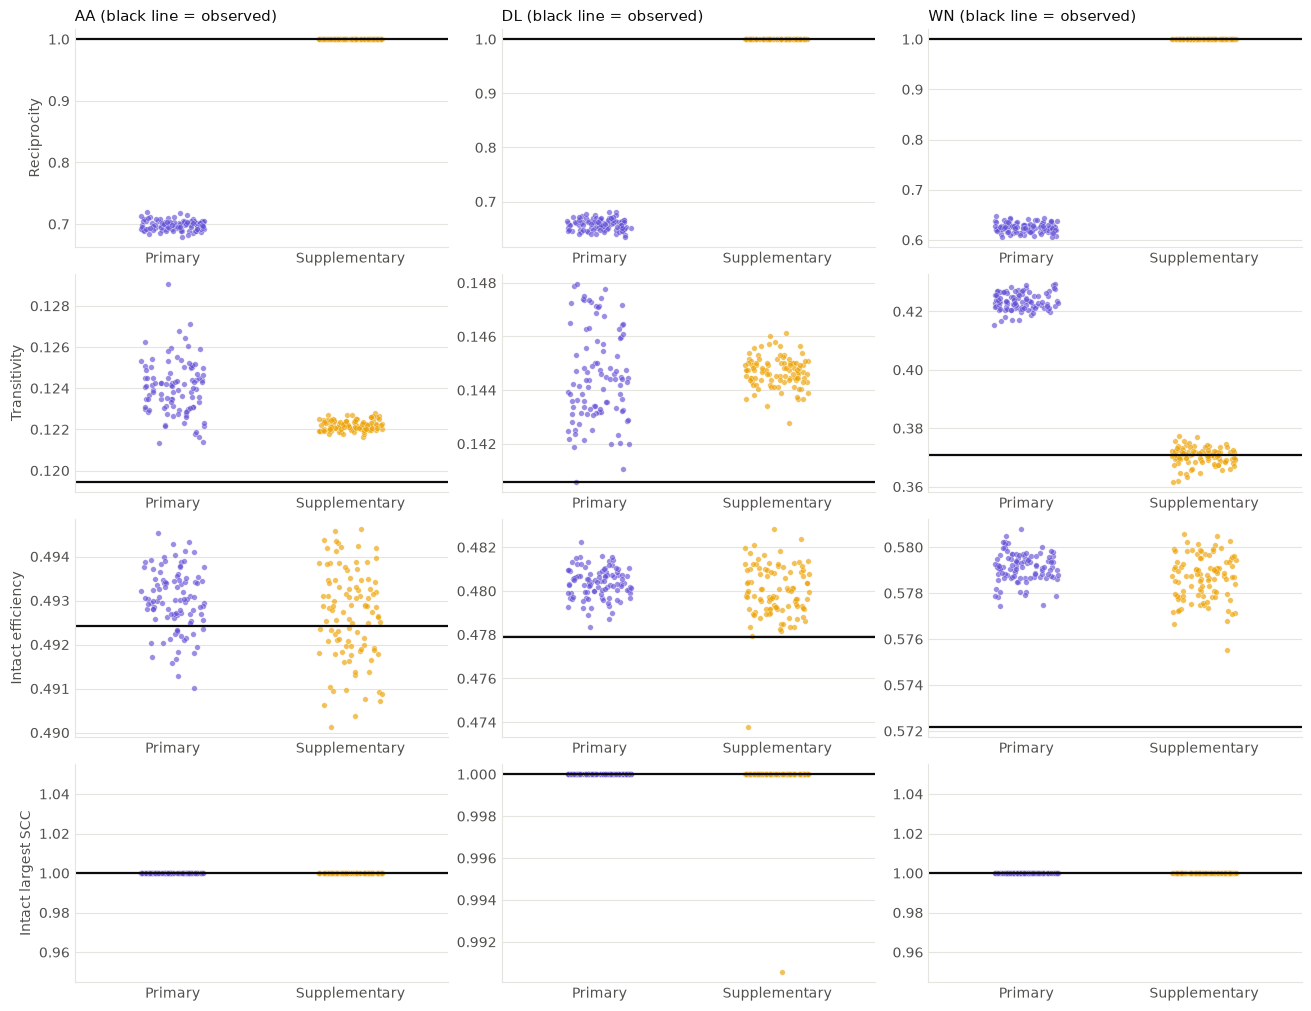

Checks recorded: 23
No observed-network removal was calculated. Steps 5 to 7 were not started.


In [ ]:
INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e5e4df"
MODEL_COLORS = {"directed": "#6250d6", "reciprocal": "#eda100"}


def style_axis(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


rng_display = np.random.default_rng(0)  # only spreads overlapping points horizontally
PANEL_MEASURES = ["Reciprocity", "Transitivity", "Intact efficiency", "Intact largest SCC"]
fig, axes = plt.subplots(len(PANEL_MEASURES), 3, figsize=(13, 10), constrained_layout=True)

for column, airline in enumerate(AIRLINES):
    for row, measure in enumerate(PANEL_MEASURES):
        ax = axes[row, column]
        for position, model in enumerate(MODELS):
            values = null_structure_df[(null_structure_df["Airline"] == airline) & (null_structure_df["Model"] == model)][measure].to_numpy(dtype=float)
            ax.scatter(position + rng_display.uniform(-0.18, 0.18, len(values)), values, s=16,
                       color=MODEL_COLORS[model], alpha=0.65, edgecolor="white", linewidth=0.3)
        ax.axhline(float(observed_structure[airline][measure]), color=INK, linewidth=1.6)
        ax.set_xticks([0, 1], ["Primary", "Supplementary"], color=MUTED)
        ax.set_xlim(-0.55, 1.55)
        if column == 0:
            ax.set_ylabel(measure, color=MUTED)
        if row == 0:
            ax.set_title(f"{airline} (black line = observed)", color=INK, fontsize=11, loc="left")
        style_axis(ax)

fig.savefig(FIGURES / "04_null_structural_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

if not EXPANSION_TRIGGERED:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), constrained_layout=True)
    for ax, airline in zip(axes, AIRLINES):
        for position, model in enumerate(MODELS):
            values = null_modularity_df[(null_modularity_df["Airline"] == airline) & (null_modularity_df["Model"] == model)]["Best modularity"].to_numpy()
            ax.scatter(position + rng_display.uniform(-0.18, 0.18, len(values)), values, s=18,
                       color=MODEL_COLORS[model], alpha=0.65, edgecolor="white", linewidth=0.3)
            ax.plot([position - 0.28, position + 0.28], [np.percentile(values, 2.5)] * 2, color=MUTED, linewidth=1.2)
            ax.plot([position - 0.28, position + 0.28], [np.percentile(values, 97.5)] * 2, color=MUTED, linewidth=1.2)
        ax.axhline(float(observed_q.loc[airline, "Best modularity"]), color=INK, linewidth=1.8)
        ax.set_xticks([0, 1], ["Primary null\n(projection not like-for-like)", "Supplementary null\n(same undirected degrees)"], color=MUTED)
        ax.set_xlim(-0.55, 1.55)
        ax.set_title(f"{airline}: best Q (black = observed; grey = 2.5–97.5%)", color=INK, fontsize=10.5, loc="left")
        style_axis(ax)
    axes[0].set_ylabel("Best modularity Q", color=MUTED)
    fig.savefig(FIGURES / "04_modularity_null_comparison.png", dpi=300, bbox_inches="tight")
    plt.show()

# NetworkX check of the SciPy connectivity calculations, on randomized networks only.
for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]
    denominator = n * (n - 1)

    for model in MODELS:
        ensemble = ENSEMBLES[(airline, model)]
        for network in range(min(3, N_NETWORKS)):
            source, target = ensemble["source"][network], ensemble["target"][network]
            A = directed_matrix(source, target, n)
            removed = RANDOM_ORDERS[airline][network][:LEVEL_K[airline][20]]
            keep = np.setdiff1d(np.arange(n), removed)
            keep_set = set(keep.tolist())
            scipy_values = evaluate_connectivity(A[keep, :][:, keep], n)
            G = nx.DiGraph()
            G.add_nodes_from(keep.tolist())
            G.add_edges_from((s, t) for s, t in zip(source.tolist(), target.tolist()) if s in keep_set and t in keep_set)
            lengths = [d for u, targets in nx.all_pairs_shortest_path_length(G) for v, d in targets.items() if u != v]
            record(f"{airline} {model} network {network}: SciPy matches NetworkX after removal", (
                np.isclose(scipy_values["Efficiency"], sum(1 / d for d in lengths) / denominator, atol=1e-12)
                and np.isclose(scipy_values["Reachability"], len(lengths) / denominator, atol=1e-12)
                and np.isclose(scipy_values["Largest SCC"], max(map(len, nx.strongly_connected_components(G))) / n, atol=1e-12)
            ))

pd.DataFrame(remaining_checks).to_csv(TABLES / "04_remaining_analysis_checks.csv", index=False)
pd.DataFrame([{"Stage": k, "Seconds": v} for k, v in stage_seconds.items()]).to_csv(TABLES / "04_remaining_analysis_runtime.csv", index=False)
pd.DataFrame([r for r in seed_registry_rows if r["Stage"] in ("random_orders", "bootstrap")]).to_csv(TABLES / "04_remaining_analysis_seed_registry.csv", index=False)
print(f"Checks recorded: {len(remaining_checks)}")
print("No observed-network removal was calculated. Steps 5 to 7 were not started.")


### Remaining Step 4 analyses: status

**Structural summaries and intact baselines** are complete for all 600 networks. **The null-only expansion assessment triggered both criteria:** E1 flagged 12 of 144 cells (8.3%) and E2 flagged 8 of 144 cells (5.6%), against a 5% threshold. Expansion is never automatic, so no additional networks were generated.

**Modularity comparisons were not run**, so the expansion decision can be reviewed first. They remain a pending supplementary analysis.

The `RuntimeWarning` shown in the null-only removal cell arises when a randomized network is so fragmented after removal that no airport pair remains connected. Only the unused average path length is affected: efficiency and reachability are correctly 0 and the largest SCC is 1 airport divided by N.

No observed-network removal was calculated, and Steps 5 to 7 have not started.

## Section 4.8: Primary-null expansion to 200 networks

This section adds chains 100 to 199 for the **primary null only**, using the same seed derivation, master seed and approved attempt counts. They are stored in separate files, so the existing 600 production networks are not altered. The supplementary null stays at 100 networks per airline.

**E1 at 200 networks** compares the first 150 networks with all 200, keeping the approved 75% split. How far the limits moved from the first 100 to all 200 is reported separately for description. E2 uses a bootstrap of all 200 networks. The thresholds and zero-width tolerance are unchanged. No expansion beyond 200 takes place.

In [ ]:
EXISTING_NETWORKS = 100
ADDITIONAL_NETWORKS = 100
FIRST_NEW_CHAIN = 100
CHECK_APPROVED_ATTEMPTS = True
APPROVED_PRIMARY_ATTEMPTS = {"AA": 452000, "DL": 301200, "WN": 358400}
expansion_seconds = {}
started = time.perf_counter()

proposal = pd.read_csv(TABLES / "04_proposed_production_swap_counts.csv")
primary = proposal[proposal["Model"] == "directed"].set_index("Airline")
expansion_chain_rows, NEW_PRIMARY = [], {}
existing_digests = {}


def file_digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


for airline in AIRLINES:
    existing_digests[airline] = {model: file_digest(NULLS / f"{airline}_{model}_null_networks.npz") for model in MODELS}


def write_expansion_records():
    pd.DataFrame(expansion_chain_rows).to_csv(TABLES / "04_production_expansion_chain_records.csv", index=False)
    pd.DataFrame([r for r in seed_registry_rows if r["Stage"] == "production"]).to_csv(
        TABLES / "04_production_expansion_seed_registry.csv", index=False
    )


for airline in AIRLINES:
    obs = OBS[airline]
    T = int(primary.loc[airline, "Proposed attempted swaps T"])
    floor = int(primary.loc[airline, "Minimum successful swaps required"])
    assert floor == 10 * obs["U"]["directed"]
    if CHECK_APPROVED_ATTEMPTS:
        assert T == APPROVED_PRIMARY_ATTEMPTS[airline], f"{airline}: attempts differ from approval"

    sources, targets = [], []

    for network in range(FIRST_NEW_CHAIN, FIRST_NEW_CHAIN + ADDITIONAL_NETWORKS):
        snapshot = run_chain(airline, "directed", T, child_seed("production", airline, "directed", network))[-1]
        enough = snapshot["successes"] >= floor
        keys = snapshot["source"] * obs["n"] + snapshot["target"]
        order = np.argsort(keys)
        expansion_chain_rows.append({
            "Airline": airline, "Model": "directed", "Network": network, "Seed entropy": MASTER_SEED,
            "Spawn key": str((STAGE_INDEX["production"], AIRLINE_INDEX[airline], MODEL_INDEX["directed"], network)),
            "Attempted swaps": T, "Successful swaps": snapshot["successes"], "Acceptance rate": snapshot["successes"] / T,
            "Minimum successful swaps required": floor, "Meets minimum successful swaps": enough,
            "Network SHA-256": hashlib.sha256(np.sort(keys).astype("<i8").tobytes()).hexdigest()
        })

        if not enough:
            write_expansion_records()
            raise StopProtocolError(
                f"{airline} directed network {network}: {snapshot['successes']} successful swaps is below "
                f"the required {floor}. Stopped; no network was regenerated."
            )

        sources.append(snapshot["source"][order])
        targets.append(snapshot["target"][order])

    NEW_PRIMARY[airline] = {"source": np.vstack(sources), "target": np.vstack(targets)}
    np.savez_compressed(
        NULLS / f"{airline}_directed_null_networks_expansion_chains_100_199.npz",
        airport_ids=obs["ids"], chain_ids=np.arange(FIRST_NEW_CHAIN, FIRST_NEW_CHAIN + ADDITIONAL_NETWORKS),
        source=obs["ids"][NEW_PRIMARY[airline]["source"]], target=obs["ids"][NEW_PRIMARY[airline]["target"]]
    )

write_expansion_records()
expansion_chain_df = pd.DataFrame(expansion_chain_rows)
expansion_seconds["Chain generation"] = time.perf_counter() - started

display(expansion_chain_df.groupby("Airline").agg(
    Networks=("Network", "count"), First_chain=("Network", "min"), Last_chain=("Network", "max"),
    Attempts=("Attempted swaps", "first"), Minimum_successes=("Successful swaps", "min"),
    Median_successes=("Successful swaps", "median"), Required=("Minimum successful swaps required", "first"),
    Mean_acceptance=("Acceptance rate", "mean")
).round(4))


,Networks,First_chain,Last_chain,Attempts,Minimum_successes,Median_successes,Required,Mean_acceptance
Airline,,,,,,,,
AA,100,100,199,452000,19718,20026.5,18080,0.0443
DL,100,100,199,301200,17036,17319.0,15060,0.0575
WN,100,100,199,358400,34819,35431.5,17920,0.0988


In [ ]:
def jaccard_values(keys):
    unique_keys, inverse = np.unique(keys, return_inverse=True)
    rows = np.repeat(np.arange(keys.shape[0]), keys.shape[1])
    X = csr_matrix((np.ones(keys.size), (rows, inverse.ravel())), shape=(keys.shape[0], len(unique_keys)))
    overlap = (X @ X.T).toarray()
    upper = np.triu_indices(keys.shape[0], k=1)
    return overlap[upper] / (2 * keys.shape[1] - overlap[upper])


validation_rows, baseline_rows, uniqueness_rows, similarity_rows, frozen_rows = [], [], [], [], []
saved_benchmark = pd.read_csv(TABLES / "04_similarity_benchmark.csv").set_index(["Airline", "Model", "Measure"])
prior_records = pd.read_csv(TABLES / "04_production_chain_records.csv")
COMBINED_PRIMARY = {}

for airline in AIRLINES:
    obs = OBS[airline]
    stored = np.load(NULLS / f"{airline}_directed_null_networks_expansion_chains_100_199.npz")
    ensemble = NEW_PRIMARY[airline]
    stored_ok = (
        np.array_equal(stored["airport_ids"], obs["ids"]) and np.array_equal(stored["source"], obs["ids"][ensemble["source"]])
        and np.array_equal(stored["target"], obs["ids"][ensemble["target"]])
        and stored["source"].shape == (ADDITIONAL_NETWORKS, obs["m"])
    )

    for index in range(ADDITIONAL_NETWORKS):
        source, target = ensemble["source"][index], ensemble["target"][index]
        keys = source * obs["n"] + target
        A = directed_matrix(source, target, obs["n"])
        components = connected_components(A, directed=True, connection="strong")[0]
        connectivity = evaluate_connectivity(A, obs["n"])
        network = FIRST_NEW_CHAIN + index
        validation_rows.append({
            "Airline": airline, "Model": "directed", "Network": network,
            "Stored file reloads exactly": stored_ok,
            "Airport set matches": bool(source.min() >= 0 and target.min() >= 0 and source.max() < obs["n"] and target.max() < obs["n"]),
            "Route count matches": len(source) == obs["m"], "No self-loops": bool((source != target).all()),
            "No duplicate directed routes": len(np.unique(keys)) == len(keys),
            "Exact in-degrees": np.array_equal(np.bincount(target, minlength=obs["n"]), obs["in"]),
            "Exact out-degrees": np.array_equal(np.bincount(source, minlength=obs["n"]), obs["out"]),
            "Strongly connected (not enforced)": components == 1
        })
        baseline_rows.append({
            "Airline": airline, "Model": "directed", "Network": network, "Intact efficiency": connectivity["Efficiency"],
            "Intact reachability": connectivity["Reachability"], "Intact largest SCC": connectivity["Largest SCC"],
            "Number of SCCs": connectivity["Number of SCCs"], "Strongly connected": components == 1,
            "Reciprocity": reciprocity_of(A)
        })

    existing = np.load(NULLS / f"{airline}_directed_null_networks.npz")
    existing_source = np.searchsorted(obs["ids"], existing["source"])
    existing_target = np.searchsorted(obs["ids"], existing["target"])
    assert existing_source.shape[0] == EXISTING_NETWORKS
    combined_source = np.vstack([existing_source, ensemble["source"]])
    combined_target = np.vstack([existing_target, ensemble["target"]])
    COMBINED_PRIMARY[airline] = {"source": combined_source, "target": combined_target}
    keys_new = ensemble["source"] * obs["n"] + ensemble["target"]
    keys_all = combined_source * obs["n"] + combined_target

    new_hashes = expansion_chain_df[expansion_chain_df["Airline"] == airline]["Network SHA-256"]
    old_hashes = prior_records[(prior_records["Airline"] == airline) & (prior_records["Model"] == "directed")]["Network SHA-256"]
    observed_hash = hashlib.sha256(obs["keys"].astype("<i8").tobytes()).hexdigest()
    all_hashes = pd.concat([old_hashes, new_hashes], ignore_index=True)
    uniqueness_rows.append({
        "Airline": airline, "New networks": len(new_hashes), "Distinct new networks": new_hashes.nunique(),
        "New networks duplicating an existing network": int(new_hashes.isin(set(old_hashes)).sum()),
        "Combined networks": len(all_hashes), "Distinct combined networks": all_hashes.nunique(),
        "Any equals observed": observed_hash in set(all_hashes)
    })

    stored_benchmark = np.load(NULLS / f"{airline}_directed_long_chain_4T_similarity_benchmark.npz")
    bench_keys = np.searchsorted(obs["ids"], stored_benchmark["source"]) * obs["n"] + np.searchsorted(obs["ids"], stored_benchmark["target"])

    for label, keys in [("New chains 100-199", keys_new), ("All 200 networks", keys_all)]:
        measures = [
            ("Pairwise Jaccard between networks", jaccard_values(keys), jaccard_values(bench_keys)),
            ("Route overlap with observed",
             np.array([np.isin(obs["keys"], k).mean() for k in keys]),
             np.array([np.isin(obs["keys"], k).mean() for k in bench_keys]))
        ]
        for measure, production, benchmark in measures:
            saved = saved_benchmark.loc[(airline, "directed", measure)]
            assert np.isclose(float(np.median(benchmark)), saved["4T benchmark median"], rtol=0, atol=1e-12)
            assert np.isclose(float(np.percentile(benchmark, 95)), saved["4T benchmark 95th percentile"], rtol=0, atol=1e-12)
            median, p95 = float(np.median(production)), float(np.percentile(production, 95))
            limit_median, limit_95 = float(saved["Production limit: median"]), float(saved["Production limit: 95th percentile"])
            similarity_rows.append({
                "Airline": airline, "Network set": label, "Measure": measure, "Values": len(production),
                "Median": median, "Limit: median": limit_median, "Median within limit": median <= limit_median,
                "95th percentile": p95, "Limit: 95th percentile": limit_95, "95th percentile within limit": p95 <= limit_95,
                "Maximum (descriptive)": float(production.max())
            })

    retained_share = np.array([(keys_all == key).any(axis=1).mean() for key in obs["keys"]])
    frozen_rows.append({
        "Airline": airline, "Model": "directed", "Networks": keys_all.shape[0], "Observed routes": obs["m"],
        "Routes kept in at least 95% of networks": int((retained_share >= 0.95).sum()),
        "Frozen route share": float((retained_share >= 0.95).mean()),
        "Mean share of networks keeping an observed route": float(retained_share.mean())
    })

expansion_validation_df = pd.DataFrame(validation_rows)
expansion_uniqueness_df = pd.DataFrame(uniqueness_rows)
expansion_similarity_df = pd.DataFrame(similarity_rows)
expansion_validation_df.to_csv(TABLES / "04_production_expansion_network_validation.csv", index=False)
pd.DataFrame(baseline_rows).to_csv(TABLES / "04_production_expansion_intact_baselines.csv", index=False)
expansion_uniqueness_df.to_csv(TABLES / "04_production_expansion_uniqueness.csv", index=False)
expansion_similarity_df.to_csv(TABLES / "04_production_expansion_similarity.csv", index=False)
pd.DataFrame(frozen_rows).to_csv(TABLES / "04_production_expansion_frozen_routes.csv", index=False)

required = ["Stored file reloads exactly", "Airport set matches", "Route count matches", "No self-loops",
            "No duplicate directed routes", "Exact in-degrees", "Exact out-degrees"]
problems = []
if not expansion_validation_df[required].all().all():
    problems.append("structural validation")
if (expansion_uniqueness_df["Distinct combined networks"] != expansion_uniqueness_df["Combined networks"]).any() or expansion_uniqueness_df["Any equals observed"].any():
    problems.append("uniqueness")
if not (expansion_similarity_df["Median within limit"].all() and expansion_similarity_df["95th percentile within limit"].all()):
    problems.append("similarity")

for airline in AIRLINES:
    for model in MODELS:
        assert file_digest(NULLS / f"{airline}_{model}_null_networks.npz") == existing_digests[airline][model]

display(expansion_uniqueness_df)
display(expansion_similarity_df.round(5))
display(expansion_validation_df.groupby("Airline").agg(Networks=("Network", "count"), Strongly_connected=("Strongly connected (not enforced)", "sum")))

if problems:
    raise StopProtocolError("Expansion check failed: " + ", ".join(problems))

print("PASS: all additional networks passed the approved checks. Existing production files are unchanged.")


,Airline,New networks,Distinct new networks,New networks duplicating an existing network,Combined networks,Distinct combined networks,Any equals observed
0,AA,100,100,0,200,200,False
1,DL,100,100,0,200,200,False
2,WN,100,100,0,200,200,False


,Airline,Network set,Measure,Values,Median,Limit: median,Median within limit,95th percentile,Limit: 95th percentile,95th percentile within limit,Maximum (descriptive)
0,AA,New chains 100-199,Pairwise Jaccard between networks,4950,0.53741,0.54741,True,0.54927,0.55927,True,0.56131
1,AA,New chains 100-199,Route overlap with observed,100,0.69994,0.71022,True,0.70805,0.71965,True,0.71515
2,AA,All 200 networks,Pairwise Jaccard between networks,19900,0.53741,0.54741,True,0.54861,0.55927,True,0.56401
3,AA,All 200 networks,Route overlap with observed,200,0.70022,0.71022,True,0.70965,0.71965,True,0.71515
4,DL,New chains 100-199,Pairwise Jaccard between networks,4950,0.49035,0.50035,True,0.50374,0.51374,True,0.51509
5,DL,New chains 100-199,Route overlap with observed,100,0.66069,0.67069,True,0.67467,0.68397,True,0.67928
6,DL,All 200 networks,Pairwise Jaccard between networks,19900,0.49109,0.50035,True,0.50374,0.51374,True,0.52352
7,DL,All 200 networks,Route overlap with observed,200,0.66268,0.67069,True,0.67533,0.68397,True,0.68194
8,WN,New chains 100-199,Pairwise Jaccard between networks,4950,0.45632,0.46632,True,0.46645,0.47705,True,0.48160
9,WN,New chains 100-199,Route overlap with observed,100,0.62333,0.63277,True,0.63449,0.64337,True,0.63616


,Networks,Strongly_connected
Airline,,
AA,100,100
DL,100,100
WN,100,100


PASS: all additional networks passed the approved checks. Existing production files are unchanged.


In [ ]:
started = time.perf_counter()
orders_table = pd.read_csv(TABLES / "04_random_removal_orders.csv").sort_values(["Airline", "Trial"])
SAVED_RANDOM_ORDERS = {
    airline: [
        np.searchsorted(OBS[airline]["ids"], np.fromiter(map(int, text.split()), dtype=np.int64))
        for text in orders_table.loc[orders_table["Airline"] == airline, "Airport order (BTS IDs)"]
    ]
    for airline in AIRLINES
}


def after_removal(A, removed, n):
    keep = np.setdiff1d(np.arange(n), removed)
    measures = evaluate_connectivity(A[keep, :][:, keep], n)
    return measures["Efficiency"], measures["Reachability"], measures["Largest SCC"]


def ordered_targets(values, ids):
    """Descending value; numerical ties (equal after 12-decimal rounding) by ascending BTS ID."""
    return np.lexsort((ids, -np.round(values, 12)))


outcome_rows, tie_rows = [], []
LEVEL_K = {a: {p: removal_count(OBS[a]["n"], p) for p in REMOVAL_PERCENTAGE_POINTS} for a in AIRLINES}

for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]

    for index in range(ADDITIONAL_NETWORKS):
        network = FIRST_NEW_CHAIN + index
        source, target = NEW_PRIMARY[airline]["source"][index], NEW_PRIMARY[airline]["target"][index]
        A = directed_matrix(source, target, n)
        intact = evaluate_connectivity(A, n)["Efficiency"]
        G = nx.DiGraph()
        G.add_nodes_from(range(n))
        G.add_edges_from(zip(source.tolist(), target.tolist()))
        scores = nx.betweenness_centrality(G, normalized=True, weight=None)
        betweenness = np.array([scores[i] for i in range(n)])
        rankings = {
            "Degree": ordered_targets((obs["in"] + obs["out"]).astype(float), obs["ids"]),
            "Betweenness": ordered_targets(betweenness, obs["ids"])
        }

        for strategy, ranking in rankings.items():
            for p, k in LEVEL_K[airline].items():
                eff, reach, scc = after_removal(A, ranking[:k], n)
                outcome_rows.append({"Airline": airline, "Network": network, "Strategy": strategy, "Level": p,
                                     "Absolute efficiency": eff, "Efficiency retention": eff / intact,
                                     "Reachability": reach, "Largest SCC": scc})

        rounded = np.round(betweenness, 12)
        ordered = rankings["Betweenness"]
        for p, k in LEVEL_K[airline].items():
            cut = rounded[ordered[k - 1]]
            group = int((rounded == cut).sum())
            above = int((rounded > cut).sum())
            tie_rows.append({"Airline": airline, "Network": network, "Level": p, "K": k,
                             "Tied group at cut-off": group, "Selected from tie": k - above,
                             "Left in tie": group - (k - above), "Cut-off betweenness is zero": bool(cut == 0)})

        random_store = {p: [] for p in REMOVAL_PERCENTAGE_POINTS}
        for order in SAVED_RANDOM_ORDERS[airline]:
            for p, k in LEVEL_K[airline].items():
                random_store[p].append(after_removal(A, order[:k], n))
        for p, results in random_store.items():
            eff, reach, scc = np.mean(results, axis=0)
            outcome_rows.append({"Airline": airline, "Network": network, "Strategy": "Random (mean of matched orders)", "Level": p,
                                 "Absolute efficiency": eff, "Efficiency retention": eff / intact,
                                 "Reachability": reach, "Largest SCC": scc})

new_outcomes_df = pd.DataFrame(outcome_rows)
new_outcomes_df.to_csv(TABLES / "04_expansion_null_only_outcomes_chains_100_199.csv", index=False)
pd.DataFrame(tie_rows).to_csv(TABLES / "04_null_betweenness_ties_at_cutoffs_chains_100_199.csv", index=False)
expansion_seconds["Null-only removal simulation"] = time.perf_counter() - started
print("New null-only outcome rows:", len(new_outcomes_df))


<local path>:105: RuntimeWarning: Mean of empty slice
  "Mean reachable path length": float(d[reachable].mean())
<local path>:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


New null-only outcome rows: 3600


In [ ]:
existing_outcomes = pd.read_csv(TABLES / "04_expansion_null_only_outcomes.csv")
assert existing_outcomes["Network"].max() < FIRST_NEW_CHAIN
combined_outcomes = pd.concat([existing_outcomes, new_outcomes_df], ignore_index=True)
TOTAL_NETWORKS = EXISTING_NETWORKS + ADDITIONAL_NETWORKS
MEASURES_200 = ["Absolute efficiency", "Efficiency retention", "Reachability", "Largest SCC"]
first_part_200 = int(0.75 * TOTAL_NETWORKS)
prior_cells = pd.read_csv(TABLES / "04_expansion_cell_assessment.csv").set_index(["Airline", "Strategy", "Level", "Measure"])
samples_200 = {}

for airline in AIRLINES:
    rng = np.random.default_rng(child_seed("bootstrap", airline, "directed", 1))
    samples_200[airline] = rng.integers(0, TOTAL_NETWORKS, size=(BOOTSTRAP_RESAMPLES, TOTAL_NETWORKS))

rows_200 = []

for (airline, strategy, level), group in combined_outcomes.groupby(["Airline", "Strategy", "Level"]):
    group = group.sort_values("Network")
    assert len(group) == TOTAL_NETWORKS
    samples = samples_200[airline]

    for measure in MEASURES_200:
        values = group[measure].to_numpy(dtype=float)
        low, high = np.percentile(values, [2.5, 97.5])
        low_part, high_part = np.percentile(values[:first_part_200], [2.5, 97.5])
        low_100, high_100 = np.percentile(values[:EXISTING_NETWORKS], [2.5, 97.5])
        boot_low, boot_high = np.percentile(values[samples], [2.5, 97.5], axis=1)
        se_low, se_high = boot_low.std(ddof=1), boot_high.std(ddof=1)
        width = high - low
        movement = max(abs(low - low_part), abs(high - high_part))
        e1_limit = 0.10 * width if width > 1e-12 else 0.001  # widths at floating-point zero use the approved tolerance
        e2_limit = 0.20 * width if width > 1e-12 else 0.001
        prior = prior_cells.loc[(airline, strategy, level, measure)]

        rows_200.append({
            "Airline": airline, "Strategy": strategy, "Level": level, "Measure": measure,
            "Null 2.5% (200)": low, "Null 97.5% (200)": high, "Interval width (200)": width,
            "Largest limit movement (first 150 vs all 200)": movement, "E1 limit": e1_limit, "E1 flagged": movement > e1_limit,
            "Bootstrap SE of lower limit": se_low, "Bootstrap SE of upper limit": se_high,
            "E2 limit": e2_limit, "E2 flagged": max(se_low, se_high) > e2_limit,
            "Movement of limits from first 100 to all 200 (descriptive)": max(abs(low - low_100), abs(high - high_100)),
            "Null 2.5% (100)": prior["Null 2.5%"], "Null 97.5% (100)": prior["Null 97.5%"], "Interval width (100)": prior["Interval width"],
            "E1 flagged at 100": bool(prior["E1 flagged"]), "E2 flagged at 100": bool(prior["E2 flagged"])
        })

assessment_200 = pd.DataFrame(rows_200)
assert len(assessment_200) == 144
assessment_200.to_csv(TABLES / "04_expansion_200_cell_assessment.csv", index=False)

e1_share, e2_share = float(assessment_200["E1 flagged"].mean()), float(assessment_200["E2 flagged"].mean())
decision_200 = pd.DataFrame([{
    "Networks per airline": TOTAL_NETWORKS, "Cells": len(assessment_200),
    "E1 flagged cells": int(assessment_200["E1 flagged"].sum()), "E1 flagged share (%)": 100 * e1_share,
    "E2 flagged cells": int(assessment_200["E2 flagged"].sum()), "E2 flagged share (%)": 100 * e2_share,
    "Flagged at 100: E1 cells": int(assessment_200["E1 flagged at 100"].sum()),
    "Flagged at 100: E2 cells": int(assessment_200["E2 flagged at 100"].sum()),
    "Trigger threshold (%)": 5, "E1 above threshold": e1_share > 0.05, "E2 above threshold": e2_share > 0.05,
    "Further expansion performed": False
}])
decision_200.to_csv(TABLES / "04_expansion_200_decision_assessment.csv", index=False)
pd.DataFrame([{"Stage": k, "Seconds": v} for k, v in expansion_seconds.items()]).to_csv(TABLES / "04_expansion_200_runtime.csv", index=False)
pd.DataFrame([r for r in seed_registry_rows if r["Stage"] == "bootstrap"]).to_csv(TABLES / "04_expansion_200_bootstrap_seed_registry.csv", index=False)

display(decision_200.T)
print("No expansion beyond 200 was performed. No observed-network removal was calculated. Steps 5 to 7 were not started.")


,0
Networks per airline,200
Cells,144
E1 flagged cells,11
E1 flagged share (%),7.638889
E2 flagged cells,6
E2 flagged share (%),4.166667
Flagged at 100: E1 cells,12
Flagged at 100: E2 cells,8
Trigger threshold (%),5
E1 above threshold,True


No expansion beyond 200 was performed. No observed-network removal was calculated. Steps 5 to 7 were not started.


### Expansion to 200 networks: status

All 300 additional primary-null networks (chains 100 to 199) met the 10 × U requirement and passed the structural, uniqueness and similarity checks. The existing production networks were not altered, and the supplementary null remains at 100 networks per airline.

**Reassessment at 200 networks:** E1 flags 11 of 144 cells (7.6%), which is above the 5% criterion, and E2 flags 6 of 144 cells (4.2%), which is below it. No expansion beyond 200 takes place.

**Correction made during this assessment.** Twelve interval widths that were truly zero appeared as about 1e-17 from floating-point rounding, so the approved 0.001 zero-width tolerance had not been applied to them. Widths at or below 1e-12 now use that tolerance. Only the assessment was rerun, from saved outcomes; no chain or network was regenerated. One flag changed: DL degree-targeted removal at 10% for largest SCC is no longer E2-flagged. The 100-network assessment had no cells affected.

No observed-network removal was calculated, and Steps 5 to 7 have not started. The supplementary modularity comparisons are still pending.

## Section 4.9: Modularity against both nulls (supplementary structural analysis)

Each null network is analysed with the same rule as the observed network: Louvain at resolution 1.0, seeds 0 to 99, keeping the highest modularity. The accepted Step 3 observed values are read from the saved table and are not recalculated. The primary null uses all 200 networks per airline, and the supplementary null uses its 100 networks per airline.

**The two comparisons answer different questions.** The primary null is projected to an undirected network, and lost reciprocity creates more undirected edges than the observed projection, so it is not like-for-like. The reciprocal-pair null has the same undirected degrees and edge count as the observed network. **Neither comparison decides H2, proves H2, or shows that communities cause resilience.** The directed primary null remains the only null deciding H2.

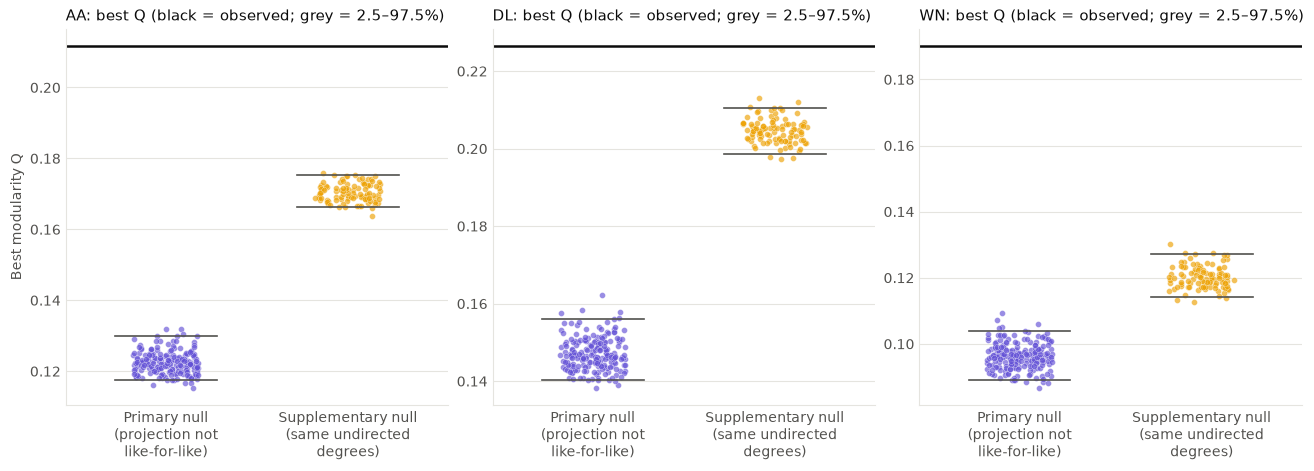

,0,1,2,3,4,5
Airline,AA,AA,DL,DL,WN,WN
Null model,Primary directed null,Supplementary reciprocal-pair null,Primary directed null,Supplementary reciprocal-pair null,Primary directed null,Supplementary reciprocal-pair null
Networks,200,100,200,100,200,100
Status,Supplementary structural analysis; no H2 verdict,Supplementary structural analysis; no H2 verdict,Supplementary structural analysis; no H2 verdict,Supplementary structural analysis; no H2 verdict,Supplementary structural analysis; no H2 verdict,Supplementary structural analysis; no H2 verdict
Observed best Q (Step 3),0.2117,0.2117,0.2265,0.2265,0.1902,0.1902
Null mean best Q,0.1225,0.1704,0.1471,0.2046,0.0963,0.1202
Null SD,0.0031,0.0025,0.0041,0.0031,0.0039,0.0034
Null 2.5%,0.1176,0.1663,0.1404,0.1986,0.089,0.1143
Null 97.5%,0.1299,0.1752,0.156,0.2106,0.104,0.1272
Observed minus null mean,0.0893,0.0413,0.0794,0.0219,0.0939,0.07


Result
PASS    10
No observed-network removal was calculated. Steps 5 to 7 were not started.


In [ ]:
EXPECTED_NETWORKS = {"directed": 200, "reciprocal": 100}
started = time.perf_counter()
modularity_checks = []


def load_null_networks(airline, model):
    obs = OBS[airline]
    stored = np.load(NULLS / f"{airline}_{model}_null_networks.npz")
    assert np.array_equal(stored["airport_ids"], obs["ids"])
    sources, targets = [stored["source"]], [stored["target"]]
    if model == "directed":
        extra = np.load(NULLS / f"{airline}_directed_null_networks_expansion_chains_100_199.npz")
        assert np.array_equal(extra["airport_ids"], obs["ids"])
        sources.append(extra["source"])
        targets.append(extra["target"])
    return np.vstack(sources), np.vstack(targets)


def best_modularity(graph):
    best, best_communities, values = -np.inf, None, []
    for seed in LOUVAIN_SEEDS:
        communities = nx.community.louvain_communities(graph, weight=None, resolution=LOUVAIN_RESOLUTION, seed=seed)
        q = nx.community.modularity(graph, communities, weight=None, resolution=LOUVAIN_RESOLUTION)
        values.append(q)
        if q > best + 1e-12:
            best, best_communities = q, communities
    return best, float(np.mean(values)), best_communities


def direct_modularity(graph, communities):
    label = {node: index for index, group in enumerate(communities) for node in group}
    m = graph.number_of_edges()
    internal = np.zeros(len(communities))
    degree_sum = np.zeros(len(communities))
    for u, v in graph.edges():
        degree_sum[label[u]] += 1
        degree_sum[label[v]] += 1
        if label[u] == label[v]:
            internal[label[u]] += 1
    return float(np.sum(internal / m - (degree_sum / (2 * m)) ** 2))


observed_undirected = {a: OBS[a]["U"]["reciprocal"] for a in AIRLINES}
modularity_rows = []

for airline in AIRLINES:
    obs = OBS[airline]
    for model in MODELS:
        source_ids, target_ids = load_null_networks(airline, model)
        assert source_ids.shape == (EXPECTED_NETWORKS[model], obs["m"])

        for network in range(EXPECTED_NETWORKS[model]):
            pairs = sorted({(min(a, b), max(a, b)) for a, b in zip(source_ids[network].tolist(), target_ids[network].tolist())})
            graph = nx.Graph()
            graph.add_nodes_from(obs["ids"].tolist())
            graph.add_edges_from(pairs)
            best, mean_q, communities = best_modularity(graph)

            if network == 0:
                modularity_checks.append({
                    "Check": f"{airline} {model}: modularity matches direct formula",
                    "Result": "PASS" if np.isclose(best, direct_modularity(graph, communities), atol=1e-12) else "FAIL"
                })

            modularity_rows.append({
                "Airline": airline, "Model": model, "Network": network, "Undirected edges": len(pairs),
                "Best modularity": best, "Mean modularity across seeds": mean_q, "Communities at best": len(communities)
            })

null_modularity_df = pd.DataFrame(modularity_rows)
null_modularity_df.to_csv(TABLES / "04_null_modularity_by_network.csv", index=False)

observed_q = pd.read_csv(TABLES / "03_louvain_binary_summary.csv").set_index("Airline")
comparison_rows = []

for (airline, model), group in null_modularity_df.groupby(["Airline", "Model"]):
    values = group["Best modularity"].to_numpy()
    observed = float(observed_q.loc[airline, "Best modularity"])
    low, high = np.percentile(values, [2.5, 97.5])
    comparison_rows.append({
        "Airline": airline, "Null model": MODEL_LABELS[model], "Networks": len(values),
        "Status": "Supplementary structural analysis; no H2 verdict",
        "Observed best Q (Step 3)": observed,
        "Null mean best Q": float(values.mean()), "Null SD": float(values.std(ddof=1)),
        "Null 2.5%": float(low), "Null 97.5%": float(high),
        "Observed minus null mean": observed - float(values.mean()),
        "Observed position": "below" if observed < low else ("above" if observed > high else "within"),
        "Observed undirected edges": observed_undirected[airline],
        "Null mean undirected edges": float(group["Undirected edges"].mean()),
        "Null mean communities at best": float(group["Communities at best"].mean())
    })

modularity_comparison_df = pd.DataFrame(comparison_rows)
modularity_comparison_df.to_csv(TABLES / "04_modularity_null_comparison.csv", index=False)

for model in MODELS:
    expected_rows = EXPECTED_NETWORKS[model] * len(AIRLINES)
    modularity_checks.append({"Check": f"{model}: expected network count", "Result": "PASS" if (null_modularity_df["Model"] == model).sum() == expected_rows else "FAIL"})
supplementary = null_modularity_df[null_modularity_df["Model"] == "reciprocal"]
modularity_checks.append({"Check": "Supplementary null edge count equals observed projection", "Result": "PASS" if all((supplementary["Airline"] == a).sum() == (supplementary[supplementary["Airline"] == a]["Undirected edges"] == observed_undirected[a]).sum() for a in AIRLINES) else "FAIL"})
modularity_checks.append({"Check": "All modularity values are finite and at most 1", "Result": "PASS" if (null_modularity_df["Best modularity"].between(-1, 1)).all() else "FAIL"})
pd.DataFrame(modularity_checks).to_csv(TABLES / "04_modularity_checks.csv", index=False)
pd.DataFrame([{"Stage": "Null modularity", "Seconds": time.perf_counter() - started}]).to_csv(TABLES / "04_modularity_runtime.csv", index=False)

INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e5e4df"
MODEL_COLORS = {"directed": "#6250d6", "reciprocal": "#eda100"}
rng_display = np.random.default_rng(0)  # only spreads overlapping points horizontally
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), constrained_layout=True)

for ax, airline in zip(axes, AIRLINES):
    for position, model in enumerate(MODELS):
        values = null_modularity_df[(null_modularity_df["Airline"] == airline) & (null_modularity_df["Model"] == model)]["Best modularity"].to_numpy()
        ax.scatter(position + rng_display.uniform(-0.18, 0.18, len(values)), values, s=18,
                   color=MODEL_COLORS[model], alpha=0.65, edgecolor="white", linewidth=0.3)
        ax.plot([position - 0.28, position + 0.28], [np.percentile(values, 2.5)] * 2, color=MUTED, linewidth=1.2)
        ax.plot([position - 0.28, position + 0.28], [np.percentile(values, 97.5)] * 2, color=MUTED, linewidth=1.2)
    ax.axhline(float(observed_q.loc[airline, "Best modularity"]), color=INK, linewidth=1.8)
    ax.set_xticks([0, 1], ["Primary null\n(projection not\nlike-for-like)", "Supplementary null\n(same undirected\ndegrees)"], color=MUTED)
    ax.set_xlim(-0.55, 1.55)
    ax.set_title(f"{airline}: best Q (black = observed; grey = 2.5–97.5%)", color=INK, fontsize=10.5, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Best modularity Q", color=MUTED)
fig.savefig(FIGURES / "04_modularity_null_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

display(modularity_comparison_df.round(4).T)
print(pd.DataFrame(modularity_checks)["Result"].value_counts().to_string())
if (pd.DataFrame(modularity_checks)["Result"] != "PASS").any():
    raise StopProtocolError("A modularity check failed.")
print("No observed-network removal was calculated. Steps 5 to 7 were not started.")


### Step 4 status: complete

**Supplementary modularity comparison.** With the same best-of-100-seeds rule, observed best modularity is above the null 2.5–97.5% range for every airline against both nulls: AA 0.212 (primary null mean 0.123; supplementary 0.170), DL 0.227 (0.147; 0.205) and WN 0.190 (0.096; 0.120).

Only the supplementary null is like-for-like, because it preserves the observed undirected degrees and edge count. The primary-null projection has about 30 to 37% more undirected edges. These results describe structure only. **They do not decide or prove H2, and they do not show that communities cause resilience.**

**Step 4 outputs.** The primary null has 200 validated networks per airline and the supplementary null has 100. At 200 primary networks, E1 flags 11 of 144 cells and E2 flags 6 of 144. No expansion beyond 200 was performed. The NetworkX comparison remains not completed for the documented structural reason.

No observed-network removal has been calculated, and Steps 5 to 7 have not started.